# Chart-to-Table with Weak Supervision
IE643 course project: a frozen encoder with a table decoder trained only on QA answers, then used as a chart question-answering tool.

**What supervision does each model use?** (this is the comparison the whole project rests on)

| model | training signal | gold tables used in training? | checkpoint chosen by |
|---|---|---|---|
| **weak** (proposed) | question programs + their answers only, plus a row count derived from *sum / mean* answer pairs | **No** | validation QA accuracy |
| **full** (baseline) | gold table: value loss on every cell + existence loss on every cell | **Yes** | validation extraction F1 (needs gold) |

The **full** model sees the gold tables, so it is an *upper bound*, not a competitor under equal supervision. Gold tables of the test split are used for evaluation of both models, never for training the weak one.

**Metrics are reported separately**: *entry existence* (does the cell exist?), *value prediction* (is the number right, 5% tolerance?) and *overall extraction* (both together), followed by an error breakdown (wrong value / missing entry / spurious entry).

In [1]:
!pip -q install -U transformers accelerate sentencepiece gradio pytesseract
# optional, only used to read axis/legend labels in the question-answering interface:
!apt-get -qq install -y tesseract-ocr > /dev/null 2>&1 || true

In [2]:
import os, io, json, math, random, time, gc, warnings, pickle, shutil
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")

QUICK_TEST = False   # True = 2-minute CPU smoke test (tiny data, raw-patch encoder instead of a pretrained one)


@dataclass
class Config:
    workdir: str = "chart2table_work"

    # data
    n_train: int = 2400
    n_val: int = 300
    n_test: int = 300
    qa_per_chart: int = 10
    R_MAX: int = 6                    # max rows (categories)
    C_MAX: int = 3                    # max columns (series)
    show_value_labels: bool = False   # False makes it harder, values must be read off the axis

    # frozen encoder used for the main experiments / the exported pickle
    encoder_name: str = "google/pix2struct-base"
    max_patches: int = 512
    # encoders compared in section 9 (heads, loss, data splits and seed are identical for all of them)
    compare_encoders: tuple = ("google/pix2struct-base", "google/siglip-base-patch16-384", "debug-patch")

    # decoder
    d_model: int = 256
    n_layers: int = 3
    n_heads: int = 8
    dropout: float = 0.1

    # training
    epochs: int = 40
    batch_size: int = 32
    lr: float = 3e-4
    weight_decay: float = 1e-2
    lambda_exist: float = 0.1         # weak model: cells used by a lookup must exist
    lambda_count: float = 0.3         # weak model: row count implied by a (sum, mean) answer pair
    lambda_exist_full: float = 0.5    # full model: BCE on the gold existence map
    tol: float = 0.05                 # 5% tolerance, same as ChartQA / PlotQA
    seed: int = 0


CFG = Config()
if QUICK_TEST:
    CFG = Config(workdir="chart2table_quick", n_train=300, n_val=60, n_test=60, epochs=8,
                 encoder_name="debug-patch", compare_encoders=("debug-patch",))
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

ENCODER_LABEL = {"google/pix2struct-base": "Pix2Struct (document-pretrained)",
                 "google/siglip-base-patch16-384": "SigLIP (generic image-text)",
                 "debug-patch": "raw pixel patches (no pretraining)"}


def seed_all(s):
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)


seed_all(CFG.seed)
print("device:", DEVICE)

device: cuda


## 1. Dataset
We generate synthetic bar and line charts with QA pairs; gold tables are kept for evaluation only.

{'train': 2400, 'val': 300, 'test': 300} 396s
[{'q': 'What is the value of Imports for 2020?', 'op': 'lookup', 'r1': 0, 'c1': 0, 'r2': 0, 'ans': 45.0}, {'q': 'What is the value of Imports for 2017?', 'op': 'lookup', 'r1': 3, 'c1': 0, 'r2': 0, 'ans': 113.0}, {'q': 'What is the sum of all series for 2022?', 'op': 'sum_row', 'r1': 1, 'c1': 1, 'r2': 0, 'ans': 165.0}]
[[ 45. 181.]
 [ 73.  92.]
 [161.  90.]
 [113.  25.]]


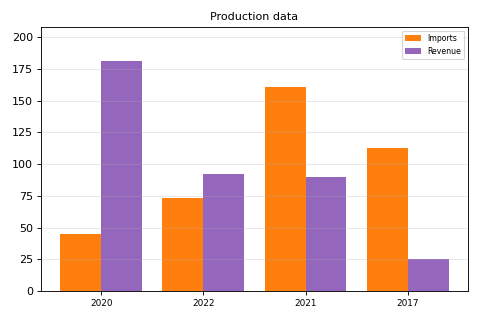

In [3]:
os.makedirs(CFG.workdir, exist_ok=True)

# Each question is a small program: (op, r1, c1, r2)
OPS = ["lookup", "sum_col", "mean_col", "max_col", "min_col", "diff", "sum_row"]
OP_ID = {op: i for i, op in enumerate(OPS)}
OP_P = [0.40, 0.12, 0.10, 0.08, 0.06, 0.14, 0.10]   # sampling probability of each op
QTYPE = {op: ("direct" if op == "lookup" else "aggregation") for op in OPS}

CATS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
        "India", "China", "Brazil", "Kenya", "Chile", "Japan", "Egypt", "Spain", "Peru", "Italy",
        "2015", "2016", "2017", "2018", "2019", "2020", "2021", "2022", "Q1", "Q2", "Q3", "Q4"]
SERIES = ["Sales", "Profit", "Cost", "Users", "Revenue", "Growth", "Exports", "Imports", "Score", "Output"]
TITLES = ["Annual summary", "Performance overview", "Regional comparison", "Quarterly report",
          "Key indicators", "Monthly trend", "Survey results", "Production data"]
PALETTE = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
           "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#393b79"]


def make_table(rng):
    n_rows = int(rng.integers(3, CFG.R_MAX + 1))
    n_cols = int(rng.integers(1, CFG.C_MAX + 1))
    vmax = float(rng.choice([20, 50, 100, 200]))

    V = rng.uniform(0.1 * vmax, 0.95 * vmax, (n_rows, n_cols))
    V = np.round(V, 1) if vmax <= 20 else np.round(V)

    cats = list(rng.choice(CATS, n_rows, replace=False))
    series = list(rng.choice(SERIES, n_cols, replace=False))
    return V, cats, series


def render_chart(V, cats, series, rng, ctype, path):
    n_rows, n_cols = V.shape
    fig, ax = plt.subplots(figsize=(6, 4), dpi=80)
    colors = list(rng.choice(PALETTE, n_cols, replace=False))
    x = np.arange(n_rows)

    if ctype == "bar":
        width = 0.8 / n_cols
        for j in range(n_cols):
            bars = ax.bar(x - 0.4 + width * (j + 0.5), V[:, j], width, color=colors[j], label=series[j])
            if CFG.show_value_labels:
                ax.bar_label(bars, fontsize=6)
    else:
        for j in range(n_cols):
            ax.plot(x, V[:, j], marker="o", color=colors[j], label=series[j])
            if CFG.show_value_labels:
                for xi, vi in zip(x, V[:, j]):
                    ax.annotate(f"{vi:g}", (xi, vi), fontsize=6, ha="center", va="bottom")

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=int(rng.choice([0, 30, 45])), fontsize=8)
    ax.set_ylim(0, V.max() * 1.15)
    if n_cols > 1:
        ax.legend(fontsize=7)
    if rng.random() < 0.5:
        ax.grid(axis="y", alpha=0.3)
    ax.set_title(str(rng.choice(TITLES)), fontsize=10)

    fig.tight_layout()
    fig.savefig(path)
    plt.close(fig)


def gen_qa(V, cats, series, rng, n):
    n_rows, n_cols = V.shape
    questions = []

    while len(questions) < n:
        op = OPS[int(rng.choice(len(OPS), p=OP_P))]
        if op == "sum_row" and n_cols < 2:
            continue   # summing a row of one series is pointless

        r1 = int(rng.integers(n_rows))
        c1 = int(rng.integers(n_cols))
        r2 = 0
        s = series[c1]

        if op == "lookup":
            ans = V[r1, c1]
            text = f"What is the value of {s} for {cats[r1]}?"
        elif op == "sum_col":
            ans = V[:, c1].sum()
            text = f"What is the total {s} across all categories?"
        elif op == "mean_col":
            ans = V[:, c1].mean()
            text = f"What is the average {s} across all categories?"
        elif op == "max_col":
            ans = V[:, c1].max()
            text = f"What is the highest value of {s}?"
        elif op == "min_col":
            ans = V[:, c1].min()
            text = f"What is the lowest value of {s}?"
        elif op == "diff":
            r2 = int(rng.choice([r for r in range(n_rows) if r != r1]))
            ans = abs(V[r1, c1] - V[r2, c1])
            text = f"What is the difference in {s} between {cats[r1]} and {cats[r2]}?"
        else:  # sum_row
            ans = V[r1, :].sum()
            text = f"What is the sum of all series for {cats[r1]}?"

        questions.append(dict(q=text, op=op, r1=r1, c1=c1, r2=r2, ans=float(round(float(ans), 4))))

    return questions


def build_split(split, n, seed):
    json_path = os.path.join(CFG.workdir, f"records_{split}.json")
    if os.path.exists(json_path):
        return json.load(open(json_path))   # already built, just reload

    img_dir = os.path.join(CFG.workdir, "charts", split)
    os.makedirs(img_dir, exist_ok=True)
    rng = np.random.default_rng(seed)
    records = []

    for i in range(n):
        V, cats, series = make_table(rng)
        ctype = str(rng.choice(["bar", "line"]))
        path = f"{img_dir}/{i:05d}.png"
        render_chart(V, cats, series, rng, ctype, path)
        records.append(dict(id=f"{split}_{i}", img=path, table=V.tolist(), cats=cats, series=series,
                            ctype=ctype, qa=gen_qa(V, cats, series, rng, CFG.qa_per_chart)))

    json.dump(records, open(json_path, "w"))
    return records


t0 = time.time()
REC = {
    "train": build_split("train", CFG.n_train, 1),
    "val":   build_split("val",   CFG.n_val,   2),
    "test":  build_split("test",  CFG.n_test,  3),
}
print({k: len(v) for k, v in REC.items()}, f"{time.time() - t0:.0f}s")

# quick look at one sample
sample = REC["train"][0]
print(sample["qa"][:3])
print(np.array(sample["table"]))
Image.open(sample["img"])

## 2. Frozen encoder
Pix2Struct is the main encoder (it is pretrained on screenshots, not on gold chart tables, unlike DePlot/MatCha). Its features are cached once. Section 9 swaps in other frozen encoders with everything else fixed.

In [4]:
class FrozenEncoder:
    """Frozen image encoder. kinds: pix2struct, siglip (generic VLM vision tower), debug (raw patches)."""

    def __init__(self, name, max_patches=512):
        self.name = name
        self.P = max_patches
        self.dtype = torch.float16 if DEVICE == "cuda" else torch.float32

        if name == "debug-patch":
            # raw 16x16x3 patches plus (row, col) position: no pretraining, used as a control / CPU smoke test
            self.dim, self.kind = 768, "debug"
            return

        if "siglip" in name.lower():
            from transformers import AutoImageProcessor, SiglipVisionModel
            self.kind = "siglip"
            self.enc = SiglipVisionModel.from_pretrained(name, torch_dtype=self.dtype).to(DEVICE).eval()
            self.proc = AutoImageProcessor.from_pretrained(name)
            self.dim = int(self.enc.config.hidden_size)
            self.P = (self.enc.config.image_size // self.enc.config.patch_size) ** 2
        else:
            from transformers import Pix2StructForConditionalGeneration, Pix2StructImageProcessor
            self.kind = "pix2struct"
            full = Pix2StructForConditionalGeneration.from_pretrained(name, torch_dtype=self.dtype)
            self.enc = full.encoder.to(DEVICE).eval()
            self.dim = int(self.enc.config.hidden_size)
            del full
            gc.collect()
            self.proc = Pix2StructImageProcessor.from_pretrained(name)

        for p in self.enc.parameters():
            p.requires_grad_(False)
        assert sum(p.requires_grad for p in self.enc.parameters()) == 0   # the encoder really is frozen

    @torch.no_grad()
    def encode(self, pils):
        if self.kind == "debug":
            gh, gw = 16, 24
            n = gh * gw
            assert self.P >= n

            feats = np.zeros((len(pils), self.P, 768), np.float32)
            masks = np.zeros((len(pils), self.P), bool)
            rows, cols = np.divmod(np.arange(n), gw)

            for k, im in enumerate(pils):
                a = np.asarray(im.convert("RGB").resize((gw * 16, gh * 16)), np.float32) / 255.0
                patches = a.reshape(gh, 16, gw, 16, 3).transpose(0, 2, 1, 3, 4).reshape(n, 768)
                patches = (patches - 0.5) * 2
                patches[:, -2] = rows / gh   # position goes in the last two channels
                patches[:, -1] = cols / gw
                feats[k, :n] = patches
                masks[k, :n] = True
            return feats.astype(np.float16), masks

        if self.kind == "siglip":
            inp = self.proc(images=pils, return_tensors="pt")
            hidden = self.enc(pixel_values=inp["pixel_values"].to(DEVICE, self.dtype)).last_hidden_state
            return hidden.float().cpu().numpy().astype(np.float16), np.ones(hidden.shape[:2], bool)

        inp = self.proc(images=pils, return_tensors="pt", max_patches=self.P)
        patches = inp["flattened_patches"].to(DEVICE, self.dtype)
        attn = inp["attention_mask"].to(DEVICE)
        hidden = self.enc(flattened_patches=patches, attention_mask=attn).last_hidden_state
        return hidden.float().cpu().numpy().astype(np.float16), attn.bool().cpu().numpy()


FEATS = {}   # (encoder name, split) -> (feature file, mask file)


def extract_split(enc, split, bs=16):
    recs = REC[split]
    N = len(recs)
    tag = enc.name.replace("/", "_")
    feat_path = os.path.join(CFG.workdir, f"feats_{tag}_{split}_{N}.npy")
    mask_path = os.path.join(CFG.workdir, f"mask_{tag}_{split}_{N}.npy")

    if os.path.exists(feat_path) and os.path.exists(mask_path):
        return feat_path, mask_path   # cached from an earlier run

    feats = np.lib.format.open_memmap(feat_path, mode="w+", dtype=np.float16, shape=(N, enc.P, enc.dim))
    masks = np.zeros((N, enc.P), bool)

    for i in range(0, N, bs):
        pils = [Image.open(r["img"]).convert("RGB") for r in recs[i:i + bs]]
        f, m = enc.encode(pils)
        feats[i:i + len(pils)] = f
        masks[i:i + len(pils)] = m
        if (i // bs) % 20 == 0:
            print(f"  {split}: {i}/{N}", end="\r")

    feats.flush()
    np.save(mask_path, masks)
    del feats
    return feat_path, mask_path


def prepare_features(enc):
    for s in ["train", "val", "test"]:
        FEATS[(enc.name, s)] = extract_split(enc, s)


t0 = time.time()
ENC = FrozenEncoder(CFG.encoder_name, CFG.max_patches)
prepare_features(ENC)
print("encoder:", CFG.encoder_name, "| feature dim:", ENC.dim, "| tokens:", ENC.P, f"| {time.time() - t0:.0f}s")

config.json:   0%|          | 0.00/4.92k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.13GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/231 [00:00<?, ?B/s]

encoder: google/pix2struct-base | feature dim: 768 | tokens: 512 | 141s


## 3. Torch datasets
The weak dataset never loads the gold table; only the eval datasets do.

In [5]:
class ChartDS(Dataset):
    def __init__(self, split, load_gold, enc_name):
        recs = REC[split]
        self.recs = recs
        N, Q = len(recs), CFG.qa_per_chart

        feat_path, mask_path = FEATS[(enc_name, split)]
        self.feats = np.load(feat_path, mmap_mode="r")
        self.mask = torch.from_numpy(np.load(mask_path))

        # question programs and answers
        self.op = torch.zeros(N, Q, dtype=torch.long)
        self.r1 = torch.zeros_like(self.op)
        self.c1 = torch.zeros_like(self.op)
        self.r2 = torch.zeros_like(self.op)
        self.ans = torch.zeros(N, Q)
        self.valid = torch.zeros(N, Q, dtype=torch.bool)

        for i, r in enumerate(recs):
            for j, q in enumerate(r["qa"][:Q]):
                self.op[i, j] = OP_ID[q["op"]]
                self.r1[i, j] = q["r1"]
                self.c1[i, j] = q["c1"]
                self.r2[i, j] = q["r2"]
                self.ans[i, j] = q["ans"]
                self.valid[i, j] = True

        self.load_gold = load_gold
        if load_gold:
            self.table = torch.zeros(N, CFG.R_MAX, CFG.C_MAX)
            self.gmask = torch.zeros(N, CFG.R_MAX, CFG.C_MAX, dtype=torch.bool)
            for i, r in enumerate(recs):
                T = torch.tensor(r["table"])
                self.table[i, :T.shape[0], :T.shape[1]] = T
                self.gmask[i, :T.shape[0], :T.shape[1]] = True

    def __len__(self):
        return len(self.recs)

    def __getitem__(self, i):
        item = dict(feats=torch.from_numpy(np.asarray(self.feats[i])), mask=self.mask[i],
                    op=self.op[i], r1=self.r1[i], c1=self.c1[i], r2=self.r2[i],
                    ans=self.ans[i], valid=self.valid[i])
        if self.load_gold:
            item.update(table=self.table[i], gmask=self.gmask[i])
        return item


def build_datasets(enc_name):
    return {
        "train_weak": ChartDS("train", False, enc_name),   # weak training: no gold table in memory
        "train_full": ChartDS("train", True, enc_name),    # full baseline + coverage analysis
        "val":  ChartDS("val", True, enc_name),
        "test": ChartDS("test", True, enc_name),
    }


DS = build_datasets(ENC.name)
assert not hasattr(DS["train_weak"], "table")
print({k: len(v) for k, v in DS.items()})

{'train_weak': 2400, 'train_full': 2400, 'val': 300, 'test': 300}


## 4. Decoder and question executor
The decoder predicts a table, and each question is run on it so the answer loss trains the cells it touched.

In [6]:
class TableDecoder(nn.Module):
    def __init__(self, enc_dim, d=256, layers=3, heads=8, R=6, C=3, drop=0.1):
        super().__init__()
        self.R, self.C = R, C

        self.proj = nn.Sequential(nn.LayerNorm(enc_dim), nn.Linear(enc_dim, d))
        self.row_emb = nn.Embedding(R, d)
        self.col_emb = nn.Embedding(C, d)

        layer = nn.TransformerDecoderLayer(d, heads, 4 * d, drop, batch_first=True, norm_first=True)
        self.tr = nn.TransformerDecoder(layer, layers)

        # one head for the cell value, one for whether the cell exists
        self.val = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Linear(d, 1))
        self.ex = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Linear(d, 1))
        nn.init.constant_(self.ex[-1].bias, 2.0)   # start by assuming every cell exists

        row_idx = torch.arange(R)[:, None].expand(R, C).reshape(-1)
        col_idx = torch.arange(C)[None].expand(R, C).reshape(-1)
        self.register_buffer("ri", row_idx)
        self.register_buffer("ci", col_idx)

    def forward(self, feats, mask):
        mem = self.proj(feats.float())
        B = mem.shape[0]
        queries = (self.row_emb(self.ri) + self.col_emb(self.ci))[None].expand(B, -1, -1)
        h = self.tr(queries, mem, memory_key_padding_mask=~mask)

        # values are positive and log-scaled so errors behave like relative errors
        V = torch.expm1(6 * torch.sigmoid(self.val(h).squeeze(-1))).view(B, self.R, self.C)
        E = self.ex(h).squeeze(-1).view(B, self.R, self.C)
        return V, E


def new_model(enc_dim=None):
    return TableDecoder(enc_dim or ENC.dim, CFG.d_model, CFG.n_layers, CFG.n_heads,
                        CFG.R_MAX, CFG.C_MAX, CFG.dropout).to(DEVICE)


def execute(V, E, op, r1, c1, r2, hard=False):
    """Run question programs on predicted tables.
    V, E are (B, R, C) and the program tensors are (B, Q). Returns answers of shape (B, Q)."""
    B, Q = op.shape
    M = torch.sigmoid(E)          # soft existence gate
    M_hard = (M > 0.5).float()
    if hard:
        M = M_hard

    bi = torch.arange(B, device=V.device)[:, None].expand(B, Q)

    # single cells
    cell = V[bi, r1, c1]
    cell2 = V[bi, r2, c1]

    # the whole column and whole row a question points at
    col_vals, col_gate = V[bi, :, c1], M[bi, :, c1]      # (B, Q, R)
    col_exists = M_hard[bi, :, c1] > 0.5
    col_exists = col_exists | (~col_exists.any(-1, keepdim=True))   # if nothing exists, use every row
    row_vals, row_gate = V[bi, r1, :], M[bi, r1, :]      # (B, Q, C)

    sum_col = (col_gate * col_vals).sum(-1)
    mean_col = sum_col / (col_gate.sum(-1) + 1e-6)
    max_col = col_vals.masked_fill(~col_exists, -1e4).max(-1).values
    min_col = col_vals.masked_fill(~col_exists, 1e4).min(-1).values
    diff = (cell - cell2).abs()
    sum_row = (row_gate * row_vals).sum(-1)

    out = torch.stack([cell, sum_col, mean_col, max_col, min_col, diff, sum_row], -1)   # same order as OPS
    return out.gather(-1, op[..., None]).squeeze(-1)


def rel_huber(pred, gold):
    scale = gold.abs() + 1
    return F.smooth_l1_loss(pred / scale, gold / scale, beta=0.05, reduction="none")


def count_loss(E, b, valid):
    """Row count implied by the answers alone: when a chart has both a 'total' and an 'average' question about
    the same series, total / average = number of rows. No gold table is used, only two QA answers.
    This is the only place the weak model gets a signal that cells do NOT exist."""
    op, c1, ans = b["op"], b["c1"], b["ans"]
    is_sum = (op == OP_ID["sum_col"]) & valid
    is_mean = (op == OP_ID["mean_col"]) & valid
    pair = is_sum[:, :, None] & is_mean[:, None, :] & (c1[:, :, None] == c1[:, None, :])   # (B, Q_sum, Q_mean)
    if not pair.any():
        return E.sum() * 0

    n_rows = ans[:, :, None] / ans[:, None, :].clamp(min=1e-6)        # implied number of rows
    B, Q = op.shape
    bi = torch.arange(B, device=E.device)[:, None].expand(B, Q)
    soft_rows = torch.sigmoid(E)[bi, :, c1].sum(-1)                   # (B, Q): soft row count of that series
    soft_rows = soft_rows[:, :, None].expand_as(n_rows)
    return F.smooth_l1_loss(soft_rows[pair], n_rows[pair])


def weak_loss(V, E, b, allowed_ops=None):
    """Uses only the question programs and gold answers, never b['table'] or b['gmask']."""
    valid = b["valid"]
    if allowed_ops is not None:
        keep = torch.tensor([OP_ID[o] for o in allowed_ops], device=V.device)
        valid = valid & torch.isin(b["op"], keep)

    pred = execute(V, E, b["op"], b["r1"], b["c1"], b["r2"])
    l_ans = (rel_huber(pred, b["ans"]) * valid).sum() / valid.sum().clamp(min=1)

    # cells named by a lookup/diff question must exist (comes from the question, not the gold table)
    ref = torch.zeros_like(E)
    B, Q = b["op"].shape
    bi = torch.arange(B, device=V.device)[:, None].expand(B, Q)
    first = valid & ((b["op"] == OP_ID["lookup"]) | (b["op"] == OP_ID["diff"]))
    second = valid & (b["op"] == OP_ID["diff"])
    ref[bi[first], b["r1"][first], b["c1"][first]] = 1
    ref[bi[second], b["r2"][second], b["c1"][second]] = 1

    if ref.sum() > 0:
        l_ex = F.binary_cross_entropy_with_logits(E[ref > 0], torch.ones_like(E[ref > 0]))
    else:
        l_ex = E.sum() * 0

    l_cnt = count_loss(E, b, valid)
    loss = l_ans + CFG.lambda_exist * l_ex + CFG.lambda_count * l_cnt
    return loss, dict(ans=l_ans.item(), ex=float(l_ex), count=float(l_cnt))


def full_loss(V, E, b):
    G, gm = b["table"], b["gmask"]
    l_val = (rel_huber(V, G) * gm).sum() / gm.sum()
    l_ex = F.binary_cross_entropy_with_logits(E, gm.float())
    return l_val + CFG.lambda_exist_full * l_ex, dict(val=l_val.item(), ex=l_ex.item())


# sanity check: running the programs on the gold tables should give the gold answers
check_ds = DS["val"]
check_V = check_ds.table[:16]
check_E = torch.full_like(check_V, 20.0)
check_E[~check_ds.gmask[:16]] = -20.0
check_pred = execute(check_V, check_E, check_ds.op[:16], check_ds.r1[:16],
                     check_ds.c1[:16], check_ds.r2[:16], hard=True)
check_err = ((check_pred - check_ds.ans[:16]).abs() * check_ds.valid[:16]).max().item()
print("executor check on gold tables, max abs error:", round(check_err, 3))
assert check_err < 0.05

# sanity check of the count signal: with the gold existence map the implied row count must be exact
_n = min(64, len(check_ds))
_b = {k: v[:_n] for k, v in {"op": check_ds.op, "c1": check_ds.c1, "ans": check_ds.ans}.items()}
_E = torch.full((_n, CFG.R_MAX, CFG.C_MAX), -20.0)
_E[check_ds.gmask[:_n]] = 20.0
print("count loss on gold existence (should be ~0):", round(count_loss(_E, _b, check_ds.valid[:_n]).item(), 4))

executor check on gold tables, max abs error: 0.0
count loss on gold existence (should be ~0): 0.0


## 5. Evaluation utilities
Three things are measured **separately**, then together:

* **Entry existence** - does the model know which cells are in the table? (accuracy over the padded grid, precision / recall / F1 of the predicted entries, shape accuracy)
* **Value prediction** - is the number right (within 5%)? `value_acc` counts every gold cell, `value_acc_found` only the cells whose existence was predicted correctly.
* **Overall extraction** - `overall_acc` = grid positions where existence *and* value are right; `extraction_f1` = F1 of entries that are both found and correct (the strict number to quote); `table_exact` = whole table right.

The error breakdown assigns every wrong grid position to one cause: **wrong value**, **missing entry** (gold cell not predicted) or **spurious entry** (predicted cell that is not in the table). QA accuracy is split by question type and by cell coverage as before.

In [7]:
@torch.no_grad()
def run_model(model, ds, bs=64):
    model.eval()
    all_V, all_E = [], []
    for b in DataLoader(ds, batch_size=bs):
        V, E = model(b["feats"].to(DEVICE), b["mask"].to(DEVICE))
        all_V.append(V.cpu())
        all_E.append(E.cpu())
    return torch.cat(all_V), torch.cat(all_E)


def qa_accuracy(V, E, ds, tol=None):
    tol = tol or CFG.tol
    pred = execute(V, E, ds.op, ds.r1, ds.c1, ds.r2, hard=True)
    correct = ((pred - ds.ans).abs() <= tol * ds.ans.abs() + 1e-6) & ds.valid

    res = {"qa_all": (correct.sum() / ds.valid.sum()).item()}

    for qtype in ["direct", "aggregation"]:
        ids = [OP_ID[o] for o in OPS if QTYPE[o] == qtype]
        m = ds.valid & torch.isin(ds.op, torch.tensor(ids))
        res[f"qa_{qtype}"] = correct[m].float().mean().item()

    for o in OPS:
        m = ds.valid & (ds.op == OP_ID[o])
        res[f"qa_op_{o}"] = correct[m].float().mean().item()
    return res


def table_metrics(V, E, ds, tol=None):
    """Existence, value and overall extraction metrics against the gold tables (evaluation only)."""
    tol = tol or CFG.tol
    G, gm = ds.table, ds.gmask
    pe = E > 0                                              # predicted entry exists
    err = (V - G).abs()
    val_ok = err <= tol * G.abs()                           # value within tolerance (only meaningful where gm)

    # --- entry existence
    tp, fp, fn = (pe & gm).sum().item(), (pe & ~gm).sum().item(), (~pe & gm).sum().item()
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    shape_ok = (pe.any(2).sum(1) == gm.any(2).sum(1)) & (pe.any(1).sum(1) == gm.any(1).sum(1))

    # --- value prediction
    value_acc = (val_ok & gm).sum().item() / gm.sum().item()                      # over every gold cell
    found = gm & pe
    value_acc_found = (val_ok & found).sum().item() / max(found.sum().item(), 1)   # over cells that were found
    value_acc_10 = ((err <= 0.10 * G.abs()) & gm).sum().item() / gm.sum().item()
    mape = (err / G.abs().clamp(min=1e-6))[gm].mean().item()

    # --- overall extraction
    entry_ok = gm & pe & val_ok                                                    # found AND correct
    pos_ok = entry_ok | (~gm & ~pe)                                                # padded cells count when left empty
    ex_prec = entry_ok.sum().item() / max(pe.sum().item(), 1)
    ex_rec = entry_ok.sum().item() / gm.sum().item()

    return dict(
        exist_acc=(pe == gm).float().mean().item(),
        exist_precision=prec, exist_recall=rec, exist_f1=2 * prec * rec / max(prec + rec, 1e-9),
        shape_acc=shape_ok.float().mean().item(),
        value_acc=value_acc, value_acc_found=value_acc_found, value_acc_10pct=value_acc_10, mape=mape,
        overall_acc=pos_ok.float().mean().item(),
        extraction_f1=2 * ex_prec * ex_rec / max(ex_prec + ex_rec, 1e-9),
        table_exact=pos_ok.all(2).all(1).float().mean().item(),
    )


def _error_parts(V, E, ds, tol=None):
    tol = tol or CFG.tol
    G, gm, pe = ds.table, ds.gmask, E > 0
    ok = (V - G).abs() <= tol * G.abs()
    return dict(correct=gm & pe & ok, wrong_value=gm & pe & ~ok, missing_entry=gm & ~pe, spurious_entry=~gm & pe)


def error_breakdown(V, E, ds, tol=None):
    """Which kind of mistake dominates? Counts over all grid positions of the evaluation split."""
    parts = _error_parts(V, E, ds, tol)
    out = {k: int(v.sum()) for k, v in parts.items()}
    out["gold_cells"] = int(ds.gmask.sum())
    kinds = ("wrong_value", "missing_entry", "spurious_entry")
    n_err = sum(out[k] for k in kinds)
    for k in kinds:
        out[k + "_per100"] = 100 * out[k] / out["gold_cells"]          # errors per 100 gold cells
        out[k + "_share"] = out[k] / max(n_err, 1)                    # share of all errors
    out["main_error"] = max(kinds, key=lambda k: out[k]) if n_err else "none"
    rel = ((V - ds.table).abs() / ds.table.abs().clamp(min=1e-6))[parts["wrong_value"]]
    out["wrong_value_median_rel_err"] = rel.median().item() if rel.numel() else 0.0
    return out


def per_chart_errors(V, E, ds):
    p = _error_parts(V, E, ds)
    return {k: p[k].sum((1, 2)) for k in ("wrong_value", "missing_entry", "spurious_entry")}


def coverage_groups(recs):
    """For each cell: 0 = no question touches it, 1 = only inside an aggregate, 2 = direct (lookup/diff),
    -1 = not a real cell."""
    g = -np.ones((len(recs), CFG.R_MAX, CFG.C_MAX), int)

    # first pass: mark every real cell, then the aggregate-only ones
    for i, r in enumerate(recs):
        R, C = np.array(r["table"]).shape
        g[i, :R, :C] = 0
        for q in r["qa"]:
            if q["op"] in ("sum_col", "mean_col", "max_col", "min_col"):
                g[i, :R, q["c1"]] = np.maximum(g[i, :R, q["c1"]], 1)
            elif q["op"] == "sum_row":
                g[i, q["r1"], :C] = np.maximum(g[i, q["r1"], :C], 1)

    # second pass: direct cells override the aggregate-only label
    for i, r in enumerate(recs):
        for q in r["qa"]:
            if q["op"] in ("lookup", "diff"):
                g[i, q["r1"], q["c1"]] = 2
            if q["op"] == "diff":
                g[i, q["r2"], q["c1"]] = 2
    return torch.from_numpy(g)


def group_cell_acc(V, ds, groups, tol=None):
    tol = tol or CFG.tol
    ok = ((V - ds.table).abs() <= tol * ds.table.abs()) & ds.gmask
    out = {}
    for name, gid in [("never-touched", 0), ("aggregate-only", 1), ("direct", 2)]:
        m = groups == gid
        acc = ok[m].float().mean().item() if m.sum() else float("nan")
        out[name] = dict(cells=int(m.sum()), cell_acc=acc)
    return out

## 6. Training
The weak and full models share one loop; the weak model is picked by validation QA accuracy.

In [8]:
def fit(mode, ds, enc_dim, epochs=None, allowed_ops=None, verbose=True):
    """Train one decoder on cached features. ds is a dict from build_datasets()."""
    assert mode in ("weak", "full")
    seed_all(CFG.seed)
    epochs = epochs or CFG.epochs

    train_ds = ds["train_weak"] if mode == "weak" else ds["train_full"]
    model = new_model(enc_dim)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG.lr, weight_decay=CFG.weight_decay)
    loader = DataLoader(train_ds, batch_size=CFG.batch_size, shuffle=True, drop_last=True)

    # short warmup, then cosine decay
    total_steps = epochs * len(loader)
    warmup = max(1, int(0.05 * total_steps))

    def lr_lambda(step):
        warm = min(1, (step + 1) / warmup)
        cosine = 0.5 * (1 + math.cos(math.pi * min(1, step / total_steps)))
        return warm * cosine

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)

    best_score, best_state, history = -1, None, []

    for ep in range(epochs):
        model.train()
        total_loss = 0
        t0 = time.time()

        for b in loader:
            b = {k: v.to(DEVICE) for k, v in b.items()}
            V, E = model(b["feats"], b["mask"])
            if mode == "weak":
                loss, parts = weak_loss(V, E, b, allowed_ops)
            else:
                loss, parts = full_loss(V, E, b)

            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()
            total_loss += loss.item()

        # validation
        Vv, Ev = run_model(model, ds["val"])
        val_qa = qa_accuracy(Vv, Ev, ds["val"])
        val_tab = table_metrics(Vv, Ev, ds["val"])

        # the weak model is selected on QA accuracy so it never needs the gold table
        score = val_qa["qa_all"] if mode == "weak" else val_tab["extraction_f1"]

        history.append(dict(epoch=ep + 1, loss=total_loss / len(loader), val_qa=val_qa["qa_all"],
                            val_qa_direct=val_qa["qa_direct"], val_qa_agg=val_qa["qa_aggregation"],
                            val_exist_f1=val_tab["exist_f1"], val_value_acc=val_tab["value_acc"],
                            val_extraction_f1=val_tab["extraction_f1"]))

        if score > best_score:
            best_score = score
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if verbose and (ep % 2 == 0 or ep == epochs - 1):
            print(f"[{mode}] ep {ep + 1:3d}/{epochs} loss {total_loss / len(loader):.4f} | "
                  f"val QA {val_qa['qa_all']:.3f} (direct {val_qa['qa_direct']:.3f}, agg {val_qa['qa_aggregation']:.3f}) | "
                  f"exist F1 {val_tab['exist_f1']:.3f} | value acc {val_tab['value_acc']:.3f} | "
                  f"{time.time() - t0:.1f}s")

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

In [9]:
weak_model, weak_hist = fit("weak", DS, ENC.dim)

[weak] ep   1/40 loss 0.8671 | val QA 0.018 (direct 0.017, agg 0.019) | exist F1 0.647 | value acc 0.022 | 16.3s
[weak] ep   3/40 loss 0.5385 | val QA 0.054 (direct 0.045, agg 0.060) | exist F1 0.728 | value acc 0.051 | 7.0s
[weak] ep   5/40 loss 0.4647 | val QA 0.050 (direct 0.043, agg 0.055) | exist F1 0.788 | value acc 0.045 | 4.5s
[weak] ep   7/40 loss 0.4363 | val QA 0.038 (direct 0.046, agg 0.033) | exist F1 0.780 | value acc 0.038 | 4.3s
[weak] ep   9/40 loss 0.4223 | val QA 0.035 (direct 0.044, agg 0.029) | exist F1 0.788 | value acc 0.041 | 4.3s
[weak] ep  11/40 loss 0.4070 | val QA 0.058 (direct 0.061, agg 0.056) | exist F1 0.789 | value acc 0.053 | 4.5s
[weak] ep  13/40 loss 0.3993 | val QA 0.043 (direct 0.047, agg 0.041) | exist F1 0.791 | value acc 0.048 | 4.4s
[weak] ep  15/40 loss 0.3821 | val QA 0.042 (direct 0.051, agg 0.035) | exist F1 0.786 | value acc 0.048 | 4.4s
[weak] ep  17/40 loss 0.3657 | val QA 0.062 (direct 0.058, agg 0.065) | exist F1 0.791 | value acc 0.05

In [10]:
full_model, full_hist = fit("full", DS, ENC.dim)

[full] ep   1/40 loss 0.9922 | val QA 0.017 (direct 0.019, agg 0.015) | exist F1 0.801 | value acc 0.025 | 4.3s
[full] ep   3/40 loss 0.5640 | val QA 0.021 (direct 0.029, agg 0.016) | exist F1 0.967 | value acc 0.033 | 4.2s
[full] ep   5/40 loss 0.4630 | val QA 0.035 (direct 0.043, agg 0.030) | exist F1 0.994 | value acc 0.043 | 4.3s
[full] ep   7/40 loss 0.4466 | val QA 0.034 (direct 0.049, agg 0.022) | exist F1 0.995 | value acc 0.046 | 4.2s
[full] ep   9/40 loss 0.3927 | val QA 0.087 (direct 0.091, agg 0.084) | exist F1 0.991 | value acc 0.071 | 4.2s
[full] ep  11/40 loss 0.3357 | val QA 0.100 (direct 0.113, agg 0.091) | exist F1 0.992 | value acc 0.092 | 4.3s
[full] ep  13/40 loss 0.2930 | val QA 0.057 (direct 0.074, agg 0.044) | exist F1 0.998 | value acc 0.083 | 4.2s
[full] ep  15/40 loss 0.2639 | val QA 0.116 (direct 0.138, agg 0.100) | exist F1 0.998 | value acc 0.111 | 4.2s
[full] ep  17/40 loss 0.2412 | val QA 0.180 (direct 0.165, agg 0.191) | exist F1 0.997 | value acc 0.135

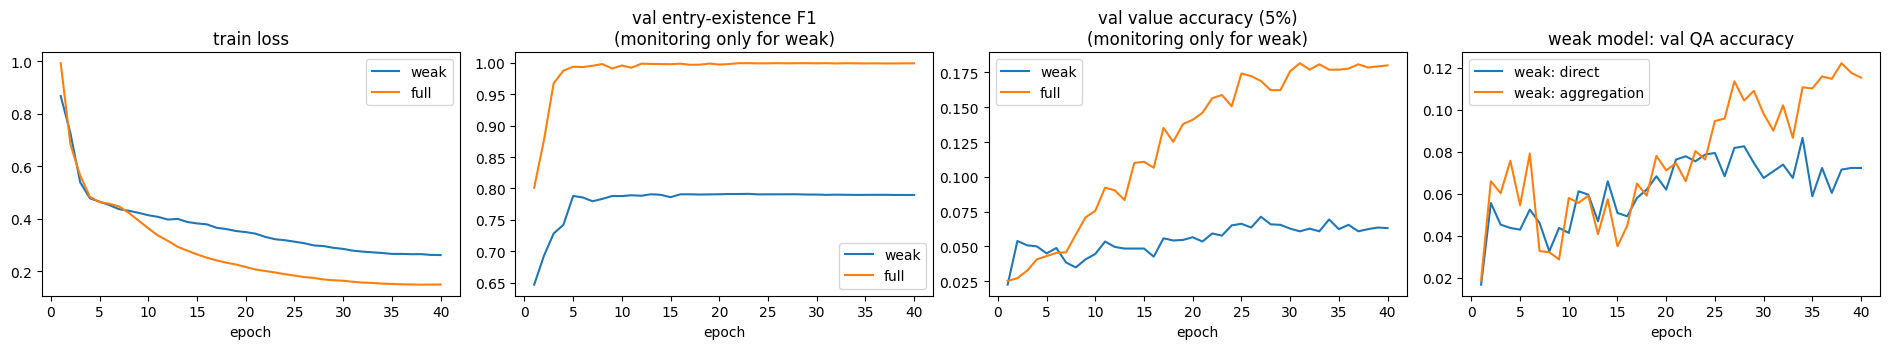

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(19, 3.6))

ax[0].plot(weak_hist.epoch, weak_hist.loss, label="weak")
ax[0].plot(full_hist.epoch, full_hist.loss, label="full")
ax[0].set_title("train loss")

ax[1].plot(weak_hist.epoch, weak_hist.val_exist_f1, label="weak")
ax[1].plot(full_hist.epoch, full_hist.val_exist_f1, label="full")
ax[1].set_title("val entry-existence F1\n(monitoring only for weak)")

ax[2].plot(weak_hist.epoch, weak_hist.val_value_acc, label="weak")
ax[2].plot(full_hist.epoch, full_hist.val_value_acc, label="full")
ax[2].set_title("val value accuracy (5%)\n(monitoring only for weak)")

ax[3].plot(weak_hist.epoch, weak_hist.val_qa_direct, label="weak: direct")
ax[3].plot(weak_hist.epoch, weak_hist.val_qa_agg, label="weak: aggregation")
ax[3].set_title("weak model: val QA accuracy")

for a in ax:
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()

## 7. Test results
Held-out charts. Entry existence, value prediction and overall extraction are reported in separate tables.

Supervision used (so the weak / full comparison is read correctly):


,trained on,gold tables in training,checkpoint chosen by
weak,QA answers + question programs (+ row count fr...,no,val QA accuracy
full,gold tables (value + existence loss on every c...,YES (upper bound),val extraction F1



(a) Entry existence


,exist_acc,exist_precision,exist_recall,exist_f1,shape_acc
model,,,,,
weak,0.762,0.683,0.999,0.812,0.357
full,0.999,0.999,0.999,0.999,0.990


(b) Value prediction (5% tolerance)


,value_acc,value_acc_found,value_acc_10pct,mape
model,,,,
weak,0.070,0.069,0.141,0.473
full,0.179,0.179,0.341,0.288


... (3 outputs left out)

,qa_all,qa_direct,qa_aggregation
model,,,
weak,0.100,0.089,0.107
full,0.229,0.210,0.242



Per-operation QA accuracy (test):


,lookup,sum_col,mean_col,max_col,min_col,diff,sum_row
model,,,,,,,
weak,0.089,0.144,0.157,0.120,0.115,0.025,0.124
full,0.210,0.307,0.319,0.386,0.157,0.117,0.192



Cost of weak supervision -> extraction F1: +0.122 | existence F1: +0.187 | value acc: +0.109
Weak vs full gap on QA, direct: +0.122 | aggregation: +0.135


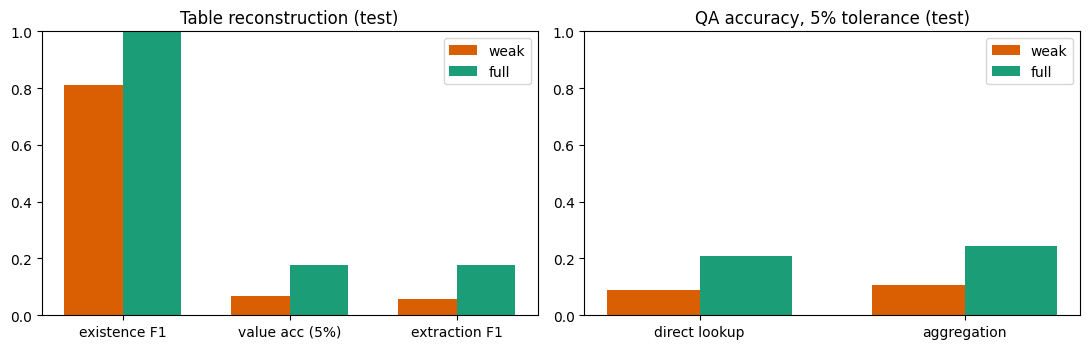

In [12]:
VT = {name: run_model(m, DS["test"]) for name, m in [("weak", weak_model), ("full", full_model)]}

rows = []
for name, (V, E) in VT.items():
    rows.append({"model": name, **table_metrics(V, E, DS["test"]), **qa_accuracy(V, E, DS["test"])})
RES = pd.DataFrame(rows).set_index("model")

print("Supervision used (so the weak / full comparison is read correctly):")
display(pd.DataFrame({
    "weak": {"trained on": "QA answers + question programs (+ row count from sum/mean answer pairs)",
             "gold tables in training": "no", "checkpoint chosen by": "val QA accuracy"},
    "full": {"trained on": "gold tables (value + existence loss on every cell)",
             "gold tables in training": "YES (upper bound)", "checkpoint chosen by": "val extraction F1"}}).T)

print("\n(a) Entry existence")
display(RES[["exist_acc", "exist_precision", "exist_recall", "exist_f1", "shape_acc"]].round(3))
print("(b) Value prediction (5% tolerance)")
display(RES[["value_acc", "value_acc_found", "value_acc_10pct", "mape"]].round(3))
print("(c) Overall extraction")
display(RES[["overall_acc", "extraction_f1", "table_exact"]].round(3))
print("(d) Question answering (5% tolerance)")
display(RES[["qa_all", "qa_direct", "qa_aggregation"]].round(3))

print("\nPer-operation QA accuracy (test):")
op_cols = [c for c in RES.columns if c.startswith("qa_op_")]
display(RES[op_cols].rename(columns=lambda c: c[6:]).round(3))

print(f"\nCost of weak supervision -> extraction F1: {RES.loc['full', 'extraction_f1'] - RES.loc['weak', 'extraction_f1']:+.3f} | "
      f"existence F1: {RES.loc['full', 'exist_f1'] - RES.loc['weak', 'exist_f1']:+.3f} | "
      f"value acc: {RES.loc['full', 'value_acc'] - RES.loc['weak', 'value_acc']:+.3f}")
print(f"Weak vs full gap on QA, direct: {RES.loc['full', 'qa_direct'] - RES.loc['weak', 'qa_direct']:+.3f} | "
      f"aggregation: {RES.loc['full', 'qa_aggregation'] - RES.loc['weak', 'qa_aggregation']:+.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
width = 0.35
for k, (name, color) in enumerate([("weak", "#d95f02"), ("full", "#1b9e77")]):
    ax[0].bar(np.arange(3) + (k - 0.5) * width,
              [RES.loc[name, "exist_f1"], RES.loc[name, "value_acc"], RES.loc[name, "extraction_f1"]],
              width, label=name, color=color)
    ax[1].bar(np.arange(2) + (k - 0.5) * width, [RES.loc[name, "qa_direct"], RES.loc[name, "qa_aggregation"]],
              width, label=name, color=color)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["existence F1", "value acc (5%)", "extraction F1"])
ax[0].set_title("Table reconstruction (test)")
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(["direct lookup", "aggregation"])
ax[1].set_title("QA accuracy, 5% tolerance (test)")
for a in ax:
    a.set_ylim(0, 1)
    a.legend()
plt.tight_layout()
plt.show()

### Propagation analysis
Cells never touched by a training question show whether the signal spread beyond the questions.

In [13]:
GR = coverage_groups(REC["train"])

rows = []
for name, m in [("weak", weak_model), ("full", full_model)]:
    V_train, _ = run_model(m, DS["train_full"])
    groups = group_cell_acc(V_train, DS["train_full"], GR)
    for group_name, d in groups.items():
        rows.append(dict(model=name, group=group_name, cells=d["cells"], cell_acc=round(d["cell_acc"], 3)))

coverage_table = pd.DataFrame(rows).pivot(index="group", columns="model", values=["cells", "cell_acc"])
display(coverage_table.loc[["direct", "aggregate-only", "never-touched"]])

cells          cell_acc       
model              full     weak     full   weak
group                                           
direct          11235.0  11235.0    0.299  0.111
aggregate-only   8797.0   8797.0    0.252  0.077
never-touched    1680.0   1680.0    0.223  0.067

### Error analysis: missing entries or wrong values?
Each grid position of the test tables is classified as correct, **wrong value** (entry found, number off by more than 5%), **missing entry** (gold cell not predicted) or **spurious entry** (predicted cell that is not in the table).

,weak,full
gold_cells,2771,2771
correct,192,495
wrong_value,2576,2273
missing_entry,3,3
spurious_entry,1282,3
wrong_value /100 gold,92.962829,82.028149
missing_entry /100 gold,0.108264,0.108264
spurious_entry /100 gold,46.264886,0.108264
main_error,wrong_value,wrong_value
wrong_value_median_rel_err,0.376812,0.21861


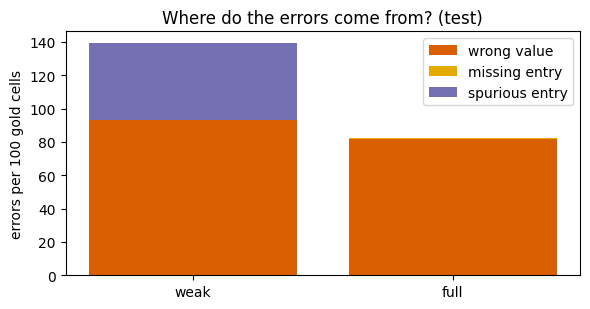

weak: main error source = wrong_value (wrong value 67%, missing 0%, spurious 33% of all errors)
full: main error source = wrong_value (wrong value 100%, missing 0%, spurious 0% of all errors)


In [14]:
ERR = pd.DataFrame({name: error_breakdown(V, E, DS["test"]) for name, (V, E) in VT.items()}).T
show = ["gold_cells", "correct", "wrong_value", "missing_entry", "spurious_entry",
        "wrong_value_per100", "missing_entry_per100", "spurious_entry_per100", "main_error", "wrong_value_median_rel_err"]
display(ERR[show].rename(columns=lambda c: c.replace("_per100", " /100 gold")).T)

fig, ax = plt.subplots(figsize=(6, 3.2))
kinds = [("wrong_value", "wrong value", "#d95f02"), ("missing_entry", "missing entry", "#e6ab02"),
         ("spurious_entry", "spurious entry", "#7570b3")]
bottom = np.zeros(len(ERR))
for k, label, color in kinds:
    vals = ERR[k + "_per100"].astype(float).values
    ax.bar(ERR.index, vals, bottom=bottom, label=label, color=color)
    bottom += vals
ax.set_ylabel("errors per 100 gold cells")
ax.set_title("Where do the errors come from? (test)")
ax.legend()
plt.tight_layout()
plt.show()

for name in ERR.index:
    r = ERR.loc[name]
    print(f"{name}: main error source = {r['main_error']} "
          f"(wrong value {r['wrong_value_share']:.0%}, missing {r['missing_entry_share']:.0%}, spurious {r['spurious_entry_share']:.0%} of all errors)")

## 8. Qualitative results
Chart, gold table and the predicted tables. Cell colours: **green** correct (within 5%), **red** wrong value, **orange** missing entry (in the gold table, not predicted), **blue** spurious entry (predicted, not in the gold table).

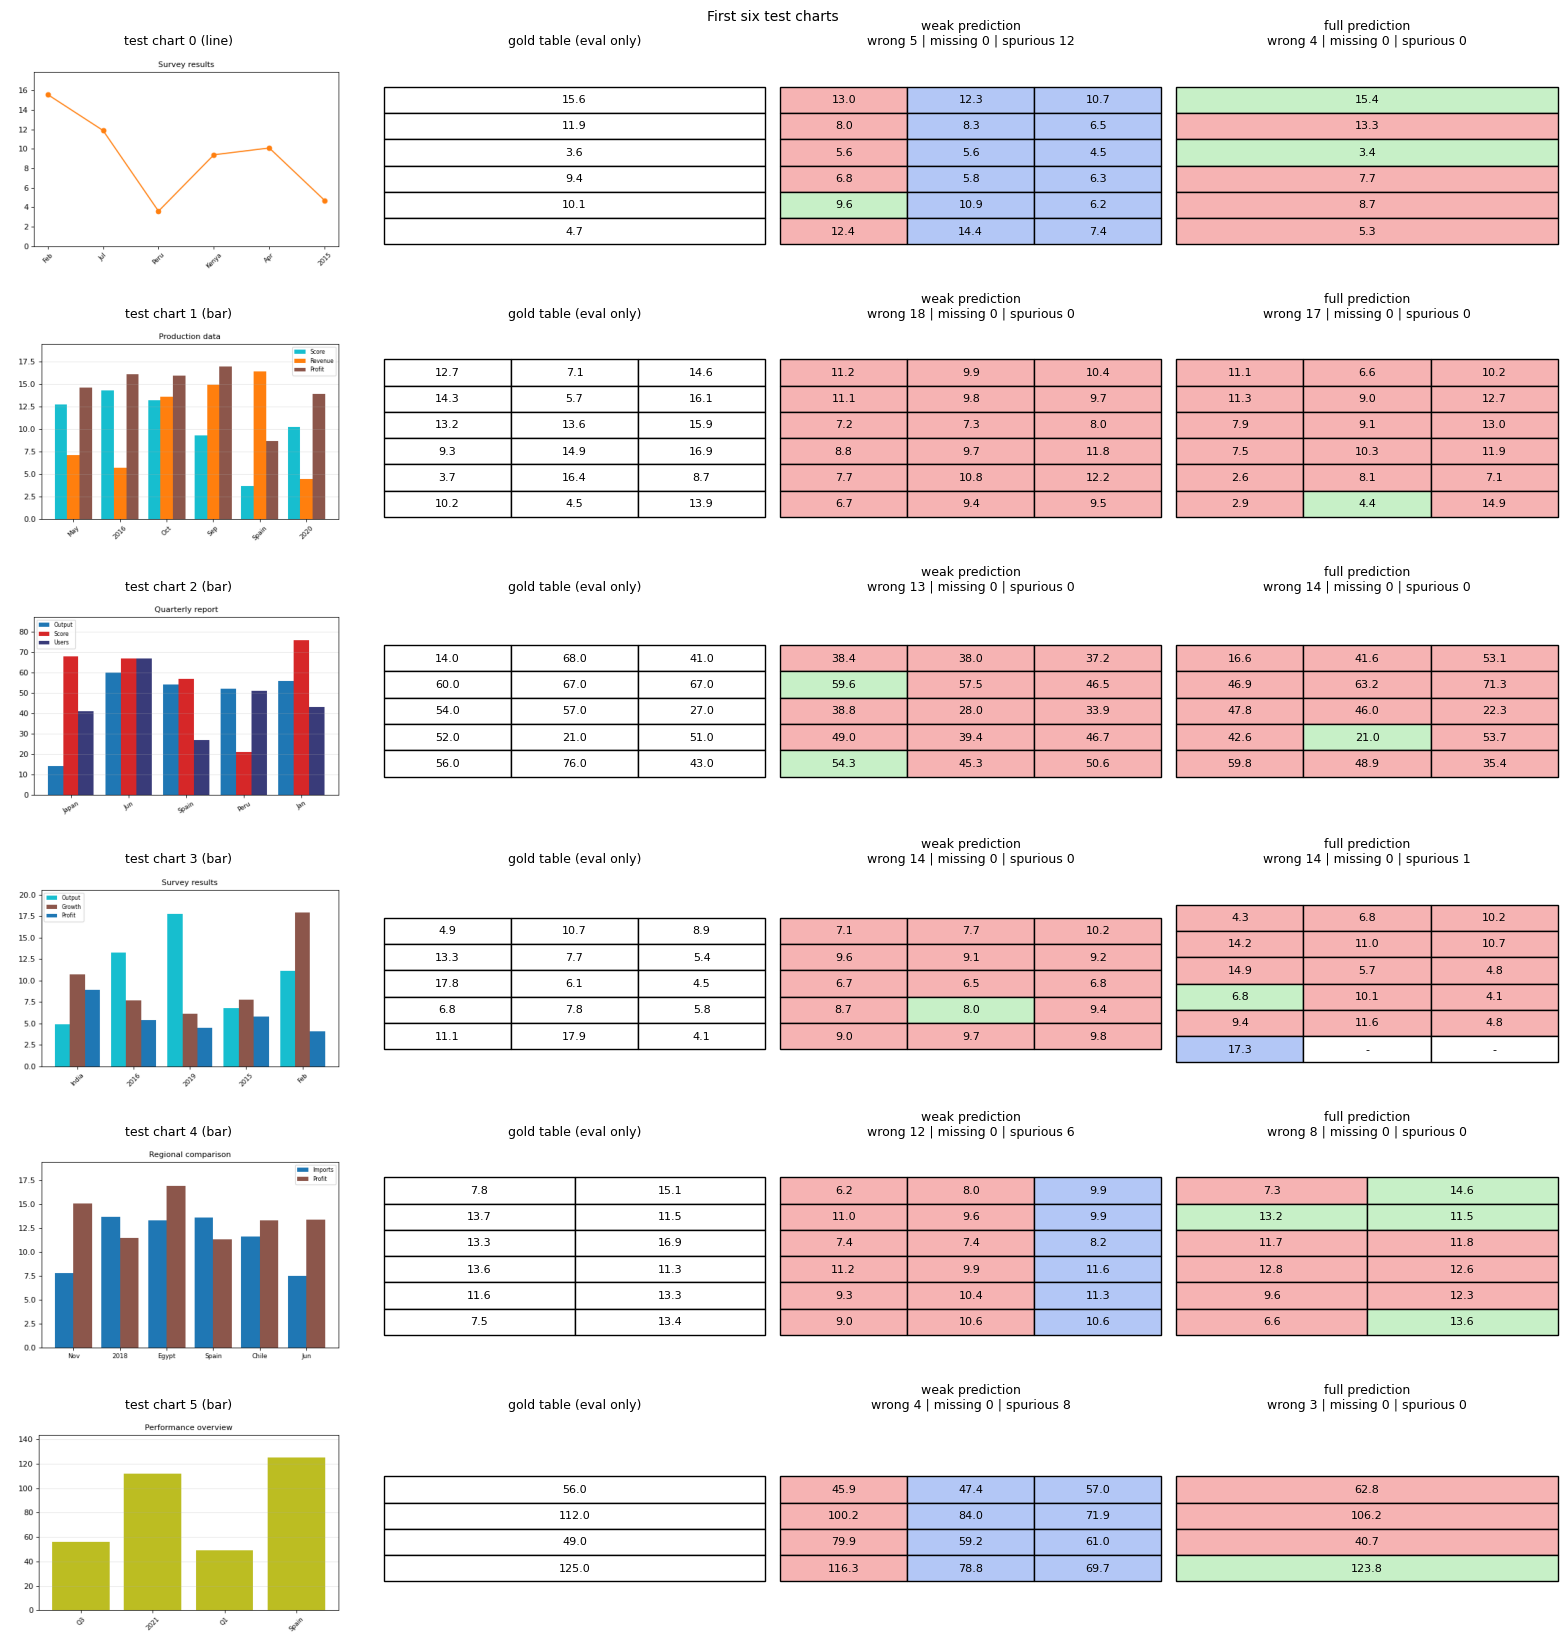

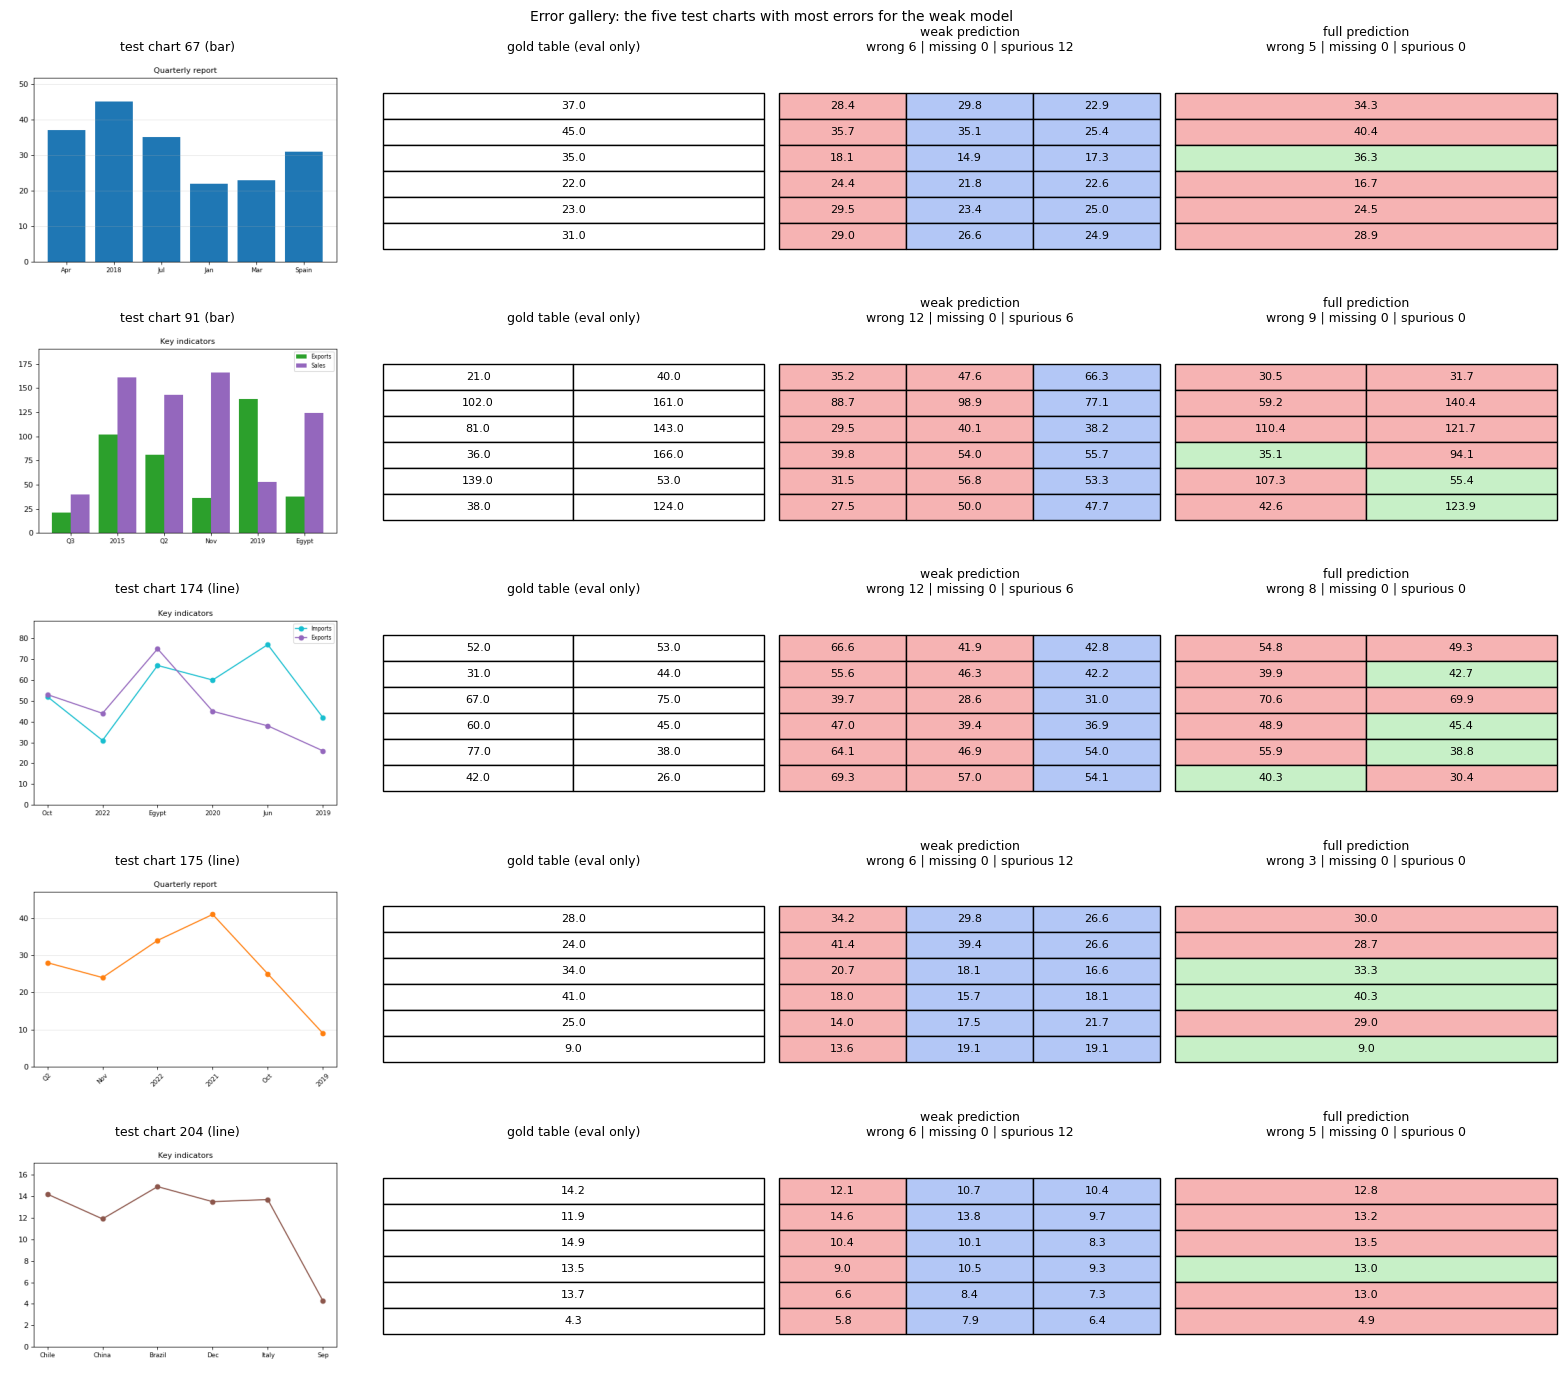

In [15]:
COLORS = dict(ok="#c7f0c7", wrong="#f6b3b3", missing="#ffd699", spurious="#b3c7f6")


def draw_table(ax, M, gold=None, title="", exist=None):
    """Draw a (predicted) table. Without gold the table is drawn plain."""
    ax.axis("off")
    pe = np.ones(M.shape, bool) if exist is None else np.asarray(exist, bool)
    gm = np.zeros(M.shape, bool)
    if gold is not None:
        gm[:gold.shape[0], :gold.shape[1]] = True
    shown = pe | gm if gold is not None else pe

    if not shown.any():
        ax.set_title(title + " (empty)", fontsize=9)
        return {}
    R = int(np.where(shown.any(1))[0].max()) + 1
    C = int(np.where(shown.any(0))[0].max()) + 1

    cell_text = [[f"{M[i, j]:.1f}" if pe[i, j] else "-" for j in range(C)] for i in range(R)]
    t = ax.table(cellText=cell_text, loc="center", cellLoc="center")
    t.scale(1, 1.3)
    t.auto_set_font_size(False)
    t.set_fontsize(8)

    counts = dict(wrong=0, missing=0, spurious=0)
    if gold is not None:
        for i in range(R):
            for j in range(C):
                if gm[i, j] and pe[i, j]:
                    ok = abs(M[i, j] - gold[i, j]) <= CFG.tol * abs(gold[i, j])
                    kind = "ok" if ok else "wrong"
                elif gm[i, j]:
                    kind = "missing"
                elif pe[i, j]:
                    kind = "spurious"
                else:
                    continue
                t[i, j].set_facecolor(COLORS[kind])
                if kind != "ok":
                    counts[kind] += 1
        title += f"\nwrong {counts['wrong']} | missing {counts['missing']} | spurious {counts['spurious']}"
    ax.set_title(title, fontsize=9)
    return counts


def show_examples(indices, models=("weak", "full"), caption=""):
    fig, axes = plt.subplots(len(indices), 2 + len(models), figsize=(4 * (2 + len(models)), 2.8 * len(indices)))
    axes = np.atleast_2d(axes)
    for row, i in enumerate(indices):
        rec = REC["test"][i]
        G = np.array(rec["table"])
        axes[row, 0].imshow(Image.open(rec["img"]))
        axes[row, 0].axis("off")
        axes[row, 0].set_title(f"test chart {i} ({rec['ctype']})", fontsize=9)
        draw_table(axes[row, 1], G, None, "gold table (eval only)")
        for k, name in enumerate(models):
            V, E = VT[name]
            draw_table(axes[row, 2 + k], V[i].numpy(), G, f"{name} prediction", exist=(E[i] > 0).numpy())
    fig.suptitle(caption, fontsize=10)
    plt.tight_layout()
    plt.show()


show_examples(list(range(6)), caption="First six test charts")

# the charts the weak model gets most wrong, with the error type visible in each title
pc = per_chart_errors(*VT["weak"], DS["test"])
total_err = pc["wrong_value"] + pc["missing_entry"] + pc["spurious_entry"]
worst = torch.argsort(total_err, descending=True)[:5].tolist()
show_examples(worst, caption="Error gallery: the five test charts with most errors for the weak model")

## 9. Ablation (optional)
Set `RUN_ABLATION = True` to see which question types matter most.

In [16]:
RUN_ABLATION = False

if RUN_ABLATION:
    ablation = {}
    settings = [
        ("lookup only", ["lookup"]),
        ("aggregation only", [o for o in OPS if o != "lookup"]),
        ("mixed (default)", None),
    ]
    for name, ops in settings:
        m, _ = fit("weak", DS, ENC.dim, epochs=max(10, CFG.epochs // 2), allowed_ops=ops, verbose=False)
        V, E = run_model(m, DS["test"])
        ablation[name] = {**table_metrics(V, E, DS["test"]), **qa_accuracy(V, E, DS["test"])}

    display(pd.DataFrame(ablation).T[["exist_f1", "value_acc", "extraction_f1", "qa_direct", "qa_aggregation"]].round(3))

## 9. Frozen-encoder comparison
Does a document-pretrained encoder help? Only the **frozen encoder** changes: the decoder heads, the QA-only loss, the data splits, the seed and the number of epochs are identical. Both the weak and the full model are trained for each encoder, and existence and value accuracy are reported separately next to the overall extraction F1.
Set `RUN_ENCODER_COMPARISON = False` to skip (it extracts features for every extra encoder).

google/pix2struct-base: done in 0s


config.json:   0%|          | 0.00/322 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  814MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SiglipVisionModel LOAD REPORT from: google/siglip-base-patch16-384
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

preprocessor_config.json:   0%|          | 0.00/368 [00:00<?, ?B/s]

google/siglip-base-patch16-384: done in 1225s
debug-patch: done in 861s


exist_f1  value_acc  \
encoder                            supervision                        
Pix2Struct (document-pretrained)   weak            0.812      0.070   
                                   full            0.999      0.179   
SigLIP (generic image-text)        weak            0.809      0.061   
                                   full            0.997      0.143   
raw pixel patches (no pretraining) weak            0.786      0.048   
                                   full            0.976      0.055   

                                                extraction_f1  qa_all  \
encoder                            supervision                          
Pix2Struct (document-pretrained)   weak                 0.056   0.100   
                                   full                 0.179   0.229   
SigLIP (generic image-text)        weak                 0.049   0.079   
                                   full                 0.142   0.177   
raw pixel patches (no pretraining) weak                 0.037   0.063   
                                   full                 0.052   0.058   

                                                qa_direct  qa_aggregation  \
encoder                            supervision                              
Pix2Struct (document-pretrained)   weak             0.089           0.107   
                                   full             0.210           0.242   
SigLIP (generic image-text)        weak             0.064           0.090   
                                   full             0.166           0.184   
raw pixel patches (no pretraining) weak             0.054           0.069   
                                   full             0.049           0.064   

                                                 main_error  
encoder                            supervision               
Pix2Struct (document-pretrained)   weak         wrong_value  
                                   full         wrong_value  
SigLIP (generic image-text)        weak         wrong_value  
                                   full         wrong_value  
raw pixel patches (no pretraining) weak         wrong_value  
                                   full         wrong_value

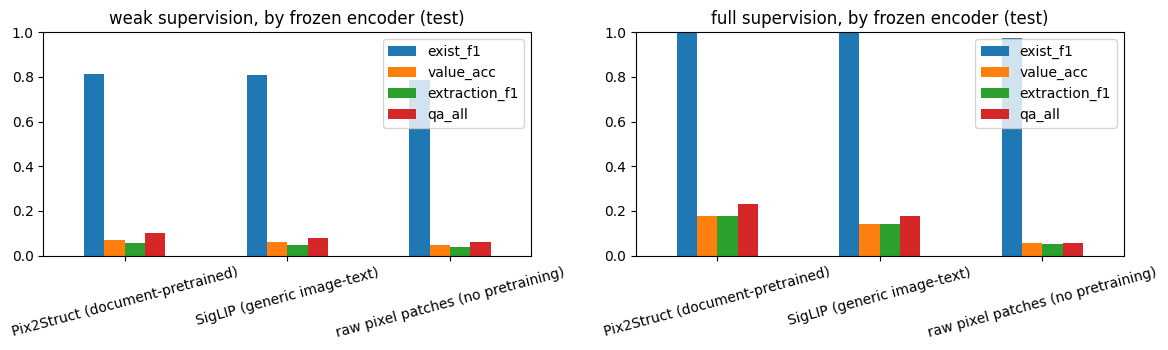

In [17]:
RUN_ENCODER_COMPARISON = True


def encoder_row(enc_name, mode, model, ds):
    V, E = run_model(model, ds["test"])
    err = error_breakdown(V, E, ds["test"])
    return {"encoder": ENCODER_LABEL.get(enc_name, enc_name), "supervision": mode,
            **table_metrics(V, E, ds["test"]), **qa_accuracy(V, E, ds["test"]),
            "main_error": err["main_error"], "wrong_value_per100": err["wrong_value_per100"],
            "missing_entry_per100": err["missing_entry_per100"], "spurious_entry_per100": err["spurious_entry_per100"]}


if RUN_ENCODER_COMPARISON:
    cmp_rows = []
    for enc_name in CFG.compare_encoders:
        t0 = time.time()
        if enc_name == ENC.name:                      # already trained above
            ds_e, m_weak, m_full = DS, weak_model, full_model
        else:
            e = FrozenEncoder(enc_name, CFG.max_patches)
            dim = e.dim
            prepare_features(e)
            del e
            gc.collect()
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
            ds_e = build_datasets(enc_name)
            m_weak, _ = fit("weak", ds_e, dim, verbose=False)
            m_full, _ = fit("full", ds_e, dim, verbose=False)
        cmp_rows += [encoder_row(enc_name, "weak", m_weak, ds_e), encoder_row(enc_name, "full", m_full, ds_e)]
        print(f"{enc_name}: done in {time.time() - t0:.0f}s")

    ENC_CMP = pd.DataFrame(cmp_rows)
    ENC_CMP.to_csv(os.path.join(CFG.workdir, "encoder_comparison.csv"), index=False)
    cols = ["exist_f1", "value_acc", "extraction_f1", "qa_all", "qa_direct", "qa_aggregation", "main_error"]
    display(ENC_CMP.set_index(["encoder", "supervision"])[cols].round(3))

    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    for a, sup in zip(ax, ["weak", "full"]):
        d = ENC_CMP[ENC_CMP.supervision == sup].set_index("encoder")
        d[["exist_f1", "value_acc", "extraction_f1", "qa_all"]].plot.bar(ax=a, rot=15)
        a.set_ylim(0, 1)
        a.set_title(f"{sup} supervision, by frozen encoder (test)")
        a.set_xlabel("")
    plt.tight_layout()
    plt.show()

## 10. Save outputs and export the pickle
`chart2table.pkl` holds both decoders (weak and full) as plain numpy arrays plus the config, so it loads without this notebook. The frozen encoder is not stored; it is downloaded from the Hugging Face hub by name on first use.

In [18]:
OUT = os.path.join(CFG.workdir, "outputs")
os.makedirs(OUT, exist_ok=True)

for name, m in [("weak", weak_model), ("full", full_model)]:
    torch.save({"state_dict": m.state_dict(), "cfg": asdict(CFG), "enc_dim": ENC.dim},
               f"{OUT}/decoder_{name}.pt")

RES.to_csv(f"{OUT}/test_results.csv")
ERR.to_csv(f"{OUT}/error_breakdown.csv")
weak_hist.to_csv(f"{OUT}/weak_history.csv")
full_hist.to_csv(f"{OUT}/full_history.csv")
json.dump(asdict(CFG), open(f"{OUT}/config.json", "w"), indent=2)


def to_numpy(sd):
    return {k: v.detach().cpu().numpy() for k, v in sd.items()}


bundle = dict(
    format="chart2table-v1",
    encoder_name=ENC.name, max_patches=CFG.max_patches, enc_dim=ENC.dim,
    cfg=asdict(CFG), ops=OPS,
    decoders={"weak": to_numpy(weak_model.state_dict()), "full": to_numpy(full_model.state_dict())},
    test_metrics=RES.round(4).to_dict(),
)
PKL = "chart2table.pkl"
with open(PKL, "wb") as f:
    pickle.dump(bundle, f)
shutil.copy(PKL, os.path.join(OUT, PKL))
print(f"saved {PKL} ({os.path.getsize(PKL) / 1e6:.1f} MB)")
print(os.listdir(OUT))

saved chart2table.pkl (28.0 MB)
['decoder_full.pt', 'full_history.csv', 'error_breakdown.csv', 'weak_history.csv', 'config.json', 'chart2table.pkl', 'decoder_weak.pt', 'test_results.csv']


### Question-answering module
This cell writes `chart2table_infer.py` next to the notebook. Together with `chart2table.pkl` it is everything needed to run the tool on any machine:
`python chart2table_infer.py --pkl chart2table.pkl`

In [19]:
%%writefile chart2table_infer.py
"""
chart2table_infer.py - ask questions about a chart image with the trained chart-to-table model.

Usage
-----
  # web interface (upload a chart, type a question)
  python chart2table_infer.py --pkl chart2table.pkl

  # one-off from the command line
  python chart2table_infer.py --pkl chart2table.pkl --image chart.png --q "What is the highest value of Sales?"

How it works
------------
1. A frozen vision encoder turns the chart image into patch features.
2. The trained table decoder predicts a (rows x series) value grid plus an
   "entry exists" flag for every cell, i.e. it reconstructs the data table.
3. A rule-based question parser turns the question into a small program
   (lookup, total, average, max, min, difference, ...) which is run on the table.

The pickle file is a plain dict of numpy arrays + config, so it loads without any
custom classes.  Only unpickle files you trust.
"""
import argparse
import gc
import os
import pickle
import re
import sys

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import Image

OPS = ["lookup", "sum_col", "mean_col", "max_col", "min_col", "diff", "sum_row"]


# --------------------------------------------------------------------------- model
class TableDecoder(nn.Module):
    """Same architecture as in the training notebook."""

    def __init__(self, enc_dim, d=256, layers=3, heads=8, R=6, C=3, drop=0.1):
        super().__init__()
        self.R, self.C = R, C
        self.proj = nn.Sequential(nn.LayerNorm(enc_dim), nn.Linear(enc_dim, d))
        self.row_emb = nn.Embedding(R, d)
        self.col_emb = nn.Embedding(C, d)
        layer = nn.TransformerDecoderLayer(d, heads, 4 * d, drop, batch_first=True, norm_first=True)
        self.tr = nn.TransformerDecoder(layer, layers)
        self.val = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Linear(d, 1))
        self.ex = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Linear(d, 1))
        row_idx = torch.arange(R)[:, None].expand(R, C).reshape(-1)
        col_idx = torch.arange(C)[None].expand(R, C).reshape(-1)
        self.register_buffer("ri", row_idx)
        self.register_buffer("ci", col_idx)

    def forward(self, feats, mask):
        mem = self.proj(feats.float())
        B = mem.shape[0]
        queries = (self.row_emb(self.ri) + self.col_emb(self.ci))[None].expand(B, -1, -1)
        h = self.tr(queries, mem, memory_key_padding_mask=~mask)
        V = torch.expm1(6 * torch.sigmoid(self.val(h).squeeze(-1))).view(B, self.R, self.C)
        E = self.ex(h).squeeze(-1).view(B, self.R, self.C)
        return V, E


class FrozenEncoder:
    """Frozen image encoder.  Supports pix2struct, siglip and a raw-patch debug encoder."""

    def __init__(self, name, max_patches=512, device=None):
        self.name = name
        self.P = max_patches
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.dtype = torch.float16 if self.device == "cuda" else torch.float32
        if name == "debug-patch":
            self.kind, self.dim = "debug", 768
        elif "siglip" in name.lower():
            from transformers import AutoImageProcessor, SiglipVisionModel
            self.kind = "siglip"
            self.enc = SiglipVisionModel.from_pretrained(name, torch_dtype=self.dtype).to(self.device).eval()
            self.proc = AutoImageProcessor.from_pretrained(name)
            self.dim = int(self.enc.config.hidden_size)
            self.P = (self.enc.config.image_size // self.enc.config.patch_size) ** 2
        else:
            from transformers import Pix2StructForConditionalGeneration, Pix2StructImageProcessor
            self.kind = "pix2struct"
            full = Pix2StructForConditionalGeneration.from_pretrained(name, torch_dtype=self.dtype)
            self.enc = full.encoder.to(self.device).eval()
            self.dim = int(self.enc.config.hidden_size)
            del full
            gc.collect()
            self.proc = Pix2StructImageProcessor.from_pretrained(name)
        if self.kind != "debug":
            for p in self.enc.parameters():
                p.requires_grad_(False)

    @torch.no_grad()
    def encode(self, pils):
        if self.kind == "debug":
            gh, gw = 16, 24
            n = gh * gw
            feats = np.zeros((len(pils), self.P, 768), np.float32)
            masks = np.zeros((len(pils), self.P), bool)
            rows, cols = np.divmod(np.arange(n), gw)
            for k, im in enumerate(pils):
                a = np.asarray(im.convert("RGB").resize((gw * 16, gh * 16)), np.float32) / 255.0
                patches = a.reshape(gh, 16, gw, 16, 3).transpose(0, 2, 1, 3, 4).reshape(n, 768)
                patches = (patches - 0.5) * 2
                patches[:, -2] = rows / gh
                patches[:, -1] = cols / gw
                feats[k, :n] = patches
                masks[k, :n] = True
            return feats.astype(np.float16), masks
        if self.kind == "siglip":
            inp = self.proc(images=pils, return_tensors="pt")
            hidden = self.enc(pixel_values=inp["pixel_values"].to(self.device, self.dtype)).last_hidden_state
            masks = np.ones(hidden.shape[:2], bool)
            return hidden.float().cpu().numpy().astype(np.float16), masks
        inp = self.proc(images=pils, return_tensors="pt", max_patches=self.P)
        patches = inp["flattened_patches"].to(self.device, self.dtype)
        attn = inp["attention_mask"].to(self.device)
        hidden = self.enc(flattened_patches=patches, attention_mask=attn).last_hidden_state
        return hidden.float().cpu().numpy().astype(np.float16), attn.bool().cpu().numpy()


# --------------------------------------------------------------------------- OCR labels (optional)
def ocr_labels(img):
    """Best-effort guess of category labels (x axis) and series labels (legend) with Tesseract.
    Returns (cats, series). Both are [] when OCR is unavailable.  Always check the result."""
    try:
        import pytesseract
        from pytesseract import Output
    except Exception:
        return [], []
    try:
        im = img.convert("RGB")
        W, H = im.size
        big = im.resize((W * 2, H * 2))
        d = pytesseract.image_to_data(big, output_type=Output.DICT, config="--psm 11")
    except Exception:
        return [], []
    words = []
    for t, c, x, y, w, h in zip(d["text"], d["conf"], d["left"], d["top"], d["width"], d["height"]):
        t = t.strip()
        if t and float(c) > 30:
            words.append((t, (x + w / 2) / (2 * W), (y + h / 2) / (2 * H)))
    num = re.compile(r"^[\d.,\-+%]+$")
    junk = lambda t: len(re.sub(r"[^A-Za-z0-9]", "", t)) < 2 or len(set(t.lower())) == 1   # legend swatches read as "mmm" etc.
    cats = sorted([w for w in words if w[2] > 0.80 and w[1] > 0.10 and not junk(w[0])], key=lambda w: w[1])
    legend = sorted([w for w in words if 0.12 < w[2] <= 0.80 and w[1] > 0.10 and not num.match(w[0]) and not junk(w[0])],
                    key=lambda w: w[2])
    return [w[0] for w in cats], [w[0] for w in legend]


# --------------------------------------------------------------------------- question parsing
ORD = {"first": 0, "1st": 0, "second": 1, "2nd": 1, "third": 2, "3rd": 2, "fourth": 3, "4th": 3,
       "fifth": 4, "5th": 4, "sixth": 5, "6th": 5, "last": -1, "final": -1}
ROW_W = r"(?:categor(?:y|ies)|bars?|points?|rows?|entry|entries|items?|x|labels?|months?|years?|countr(?:y|ies)|quarters?|regions?)"
COL_W = r"(?:series|lines?|columns?|legend|groups?)"
ORD_RE = "|".join(ORD)

SUPPORTED = ("value of a series for a category, total / average / median / highest / lowest / range of a series, "
             "sum of all series for a category, difference / ratio / percent change between two categories, "
             "which category is highest or lowest, which of two categories is higher, "
             "and how many categories or series there are")


def _find_labels(ql, labels):
    hits = []
    for i, lab in enumerate(labels or []):
        lab = str(lab).strip().lower()
        if not lab:
            continue
        for m in re.finditer(r"(?<![\w])" + re.escape(lab) + r"(?![\w])", ql):
            hits.append((m.start(), i))
    return hits


def _ordinal_refs(ql):
    rows, cols = [], []
    for m in re.finditer(r"\b(" + ORD_RE + r")\s+(?:\w+\s+)?(" + ROW_W + "|" + COL_W + r")\b", ql):
        idx = ORD[m.group(1)]
        (cols if re.fullmatch(COL_W, m.group(2)) else rows).append((m.start(), idx))
    for m in re.finditer(r"\b(" + ROW_W + "|" + COL_W + r")\s*(?:number|no\.?|#)?\s*(\d{1,2})\b", ql):
        idx = int(m.group(2)) - 1
        (cols if re.fullmatch(COL_W, m.group(1)) else rows).append((m.start(), idx))
    return rows, cols


def parse_question(question, cats, series):
    """Return dict(op, rows, col, extreme).  op is None when the question is not understood."""
    ql = question.lower().strip().rstrip("?.! ")
    o_rows, o_cols = _ordinal_refs(ql)
    rows = sorted(_find_labels(ql, cats) + o_rows)
    cols = sorted(_find_labels(ql, series) + o_cols)
    rows = [i for _, i in rows]
    col = cols[0][1] if cols else None

    has = lambda *ws: any(re.search(r"\b" + w + r"\b", ql) for w in ws)
    hi = has("highest", "maximum", "max", "largest", "biggest", "greatest", "peak", "tallest", "most")
    lo = has("lowest", "minimum", "min", "smallest", "least", "shortest")
    extreme = "max" if hi else ("min" if lo else None)
    prog = dict(op=None, rows=rows, col=col, extreme=extreme)

    if re.search(r"how many\b.*\b(series|lines|columns|legend|groups)", ql):
        prog["op"] = "count_cols"
    elif re.search(r"how many\b.*\b(categor|rows|bars|points|entries|items|x|months|years|countries|quarters|regions)", ql):
        prog["op"] = "count_rows"
    elif re.search(r"\bwhich\b", ql) and extreme and len(rows) < 2:
        prog["op"] = "arg" + extreme
    elif len(rows) >= 2 and has("higher", "greater", "larger", "bigger", "lower", "smaller", "less", "fewer", "more") \
            and not has("difference", "differ", "gap") and not re.search(r"how much (more|less)", ql):
        prog["op"] = "compare_lo" if has("lower", "smaller", "less", "fewer") else "compare_hi"
    elif len(rows) >= 2 and ("%" in ql or has("percent", "percentage")):
        prog["op"] = "pct_change"
    elif len(rows) >= 2 and has("ratio"):
        prog["op"] = "ratio"
    elif len(rows) >= 2 and (has("difference", "differ", "gap", "change") or re.search(r"how much (more|less)", ql)):
        prog["op"] = "diff"
    elif re.search(r"all (the )?series|across (all )?series|every series|all lines", ql) and rows:
        prog["op"] = "sum_row"
    elif has("total", "sum", "add", "combined") and len(rows) == 1 and col is None:
        prog["op"] = "sum_row"
    elif has("range", "spread"):
        prog["op"] = "range_col"
    elif has("median"):
        prog["op"] = "median_col"
    elif has("total", "sum", "combined"):
        prog["op"] = "sum_col"
    elif has("average", "mean", "avg"):
        prog["op"] = "mean_col"
    elif extreme == "max":
        prog["op"] = "max_col"
    elif extreme == "min":
        prog["op"] = "min_col"
    elif len(rows) >= 1:
        prog["op"] = "lookup"
    return prog


def _fmt(x):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "n/a"
    s = f"{x:.2f}".rstrip("0").rstrip(".")
    return s if s not in ("", "-0") else "0"


def run_program(T, prog, cat_names, ser_names):
    """T: (n_rows, n_cols) float array with NaN for missing cells.  Returns (answer text, details text)."""
    n_rows, n_cols = T.shape
    op = prog["op"]

    def ridx(i):
        j = n_rows + i if i < 0 else i
        if not 0 <= j < n_rows:
            raise IndexError(f"the model found only {n_rows} categories, so category #{i + 1} does not exist")
        return j

    def cidx(i):
        j = n_cols + i if i < 0 else i
        if not 0 <= j < n_cols:
            raise IndexError(f"the model found only {n_cols} series, so series #{i + 1} does not exist")
        return j

    if op == "count_rows":
        return str(n_rows), "number of categories (x-axis entries) the model found"
    if op == "count_cols":
        return str(n_cols), "number of series (bars/lines per category) the model found"

    cols = [cidx(prog["col"])] if prog["col"] is not None else list(range(n_cols))
    rows = [ridx(i) for i in prog["rows"]]

    def per_col(fn, what):
        outs, det = [], []
        for c in cols:
            v = fn(c)
            outs.append((ser_names[c], v))
            det.append(f"{what} of {ser_names[c]}")
        if len(outs) == 1:
            v = outs[0][1]
            return (_fmt(v) if not isinstance(v, str) else v), det[0]
        return "; ".join(f"{n}: {_fmt(v) if not isinstance(v, str) else v}" for n, v in outs), \
            f"{what}, per series"

    col_ = lambda c: T[:, c]
    with np.errstate(all="ignore"):
        if op == "lookup":
            r = rows[0]
            return per_col(lambda c: T[r, c], f"value at {cat_names[r]}")
        if op == "diff":
            r1, r2 = rows[0], rows[1]
            return per_col(lambda c: abs(T[r1, c] - T[r2, c]), f"|{cat_names[r1]} - {cat_names[r2]}|")
        if op == "ratio":
            r1, r2 = rows[0], rows[1]
            return per_col(lambda c: T[r1, c] / T[r2, c], f"{cat_names[r1]} / {cat_names[r2]}")
        if op == "pct_change":
            r1, r2 = rows[0], rows[1]
            return per_col(lambda c: 100 * (T[r2, c] - T[r1, c]) / T[r1, c],
                           f"percent change from {cat_names[r1]} to {cat_names[r2]}")
        if op in ("compare_hi", "compare_lo"):
            r1, r2 = rows[0], rows[1]
            pick = np.nanargmax if op == "compare_hi" else np.nanargmin

            def f(c):
                pair = [T[r1, c], T[r2, c]]
                return [cat_names[r1], cat_names[r2]][int(pick(pair))]
            return per_col(f, "category with the " + ("higher" if op == "compare_hi" else "lower") + " value")
        if op == "sum_row":
            r = rows[0]
            return _fmt(np.nansum(T[r, :])), f"sum of all series for {cat_names[r]}"
        if op == "sum_col":
            return per_col(lambda c: np.nansum(col_(c)), "total")
        if op == "mean_col":
            return per_col(lambda c: np.nanmean(col_(c)), "average")
        if op == "median_col":
            return per_col(lambda c: np.nanmedian(col_(c)), "median")
        if op == "max_col":
            return per_col(lambda c: np.nanmax(col_(c)), "highest value")
        if op == "min_col":
            return per_col(lambda c: np.nanmin(col_(c)), "lowest value")
        if op == "range_col":
            return per_col(lambda c: np.nanmax(col_(c)) - np.nanmin(col_(c)), "range (max - min)")
        if op in ("argmax", "argmin"):
            pick = np.nanargmax if op == "argmax" else np.nanargmin
            return per_col(lambda c: cat_names[int(pick(col_(c)))],
                           "category with the " + ("highest" if op == "argmax" else "lowest") + " value")
    raise ValueError("unsupported operation")


# --------------------------------------------------------------------------- the pipeline
class ChartQA:
    """Load a chart2table pickle and answer questions about chart images."""

    def __init__(self, pkl_path, device=None, model="weak", encoder=None):
        with open(pkl_path, "rb") as f:
            self.bundle = pickle.load(f)
        assert self.bundle.get("format") == "chart2table-v1", "not a chart2table pickle"
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        cfg = self.bundle["cfg"]
        self.R, self.C = cfg["R_MAX"], cfg["C_MAX"]
        self.default_model = model
        self.encoder = encoder or FrozenEncoder(self.bundle["encoder_name"], self.bundle["max_patches"], self.device)
        self.models = {}
        for name, sd in self.bundle["decoders"].items():
            m = TableDecoder(self.bundle["enc_dim"], cfg["d_model"], cfg["n_layers"], cfg["n_heads"],
                             self.R, self.C, cfg["dropout"])
            m.load_state_dict({k: torch.from_numpy(np.array(v)) for k, v in sd.items()})
            self.models[name] = m.to(self.device).eval()

    @torch.no_grad()
    def predict_grid(self, img, model=None):
        model = model or self.default_model
        f, m = self.encoder.encode([img.convert("RGB")])
        V, E = self.models[model](torch.from_numpy(f).to(self.device), torch.from_numpy(m).to(self.device))
        return V[0].cpu().numpy(), E[0].cpu().numpy()

    def extract_table(self, img, model=None, cats=None, series=None):
        """Reconstruct the data table.  Returns (DataFrame, array T with NaN gaps, warnings)."""
        V, E = self.predict_grid(img, model)
        ex = E > 0
        warn = []
        rows, cols = np.where(ex.any(1))[0], np.where(ex.any(0))[0]
        if len(rows) == 0 or len(cols) == 0:
            rows, cols = np.arange(self.R), np.arange(self.C)
            warn.append("the model found no table entries; showing the raw grid")
        T = V[np.ix_(rows, cols)].astype(float)
        T[~ex[np.ix_(rows, cols)]] = np.nan
        cat_names = [str(cats[i]) if cats and i < len(cats) else f"category {i + 1}" for i in range(len(rows))]
        ser_names = [str(series[i]) if series and i < len(series) else f"series {i + 1}" for i in range(len(cols))]
        df = pd.DataFrame(np.round(T, 2), index=cat_names, columns=ser_names)
        return df, T, warn

    def answer(self, img, question, cats=None, series=None, model=None, use_ocr=True):
        """Answer one question.  cats / series are optional lists of labels (x axis left to right,
        legend top to bottom); if omitted, OCR is tried and ordinal references still work
        ("the second series", "third category")."""
        if isinstance(img, (str, os.PathLike)):
            img = Image.open(img)
        warnings = []
        df0, T0, w0 = self.extract_table(img, model)
        warnings += w0
        n_rows, n_cols = T0.shape

        cats = [c.strip() for c in cats if c.strip()] if cats else []
        series = [s.strip() for s in series if s.strip()] if series else []
        if use_ocr and (not cats or not series):
            oc, osr = ocr_labels(img)
            if not cats and oc:
                if len(oc) == n_rows:
                    cats = oc
                else:
                    warnings.append(f"OCR read {len(oc)} x-axis labels but the model found {n_rows} categories; "
                                    "ignoring OCR labels (type them in to be safe)")
            if not series and osr:
                if len(osr) == n_cols:
                    series = osr
                else:
                    warnings.append(f"OCR read {len(osr)} legend labels but the model found {n_cols} series; "
                                    "ignoring OCR labels")
        if n_cols == 1 and not series:
            series = []
        for nm, lab, n in (("category", cats, n_rows), ("series", series, n_cols)):
            if lab and len(lab) != n:
                warnings.append(f"you gave {len(lab)} {nm} labels but the model found {n}; labels are matched by position")

        df, T, _ = self.extract_table(img, model, cats, series)
        cat_names, ser_names = list(df.index), list(df.columns)
        prog = parse_question(question, cats, series)

        if prog["op"] is None:
            ans = ("I could not understand that question. I can answer: " + SUPPORTED + ". "
                   "Refer to categories/series by label (if labels are given) or by position, "
                   "e.g. 'the second series' or 'the third category'.")
            return dict(answer=ans, details="", table=df, program=prog, warnings=warnings, ok=False)
        if prog["op"] in ("lookup", "diff", "ratio", "pct_change", "compare_hi", "compare_lo", "sum_row") \
                and len(prog["rows"]) < (1 if prog["op"] in ("lookup", "sum_row") else 2):
            ans = ("I need to know which category you mean. Type the category labels in the labels box "
                   "or say e.g. 'the first category'.")
            return dict(answer=ans, details="", table=df, program=prog, warnings=warnings, ok=False)
        try:
            text, det = run_program(T, prog, cat_names, ser_names)
        except (IndexError, ValueError) as e:
            return dict(answer=f"Cannot answer: {e}.", details="", table=df, program=prog, warnings=warnings, ok=False)
        return dict(answer=text, details=det, table=df, program=prog, warnings=warnings, ok=True)


# --------------------------------------------------------------------------- UI
def launch_ui(pkl_path, encoder=None, share=False, server_port=None):
    import gradio as gr
    qa = ChartQA(pkl_path, encoder=encoder)
    models = list(qa.models)

    def fn(image, question, cats_txt, series_txt, model, use_ocr):
        if image is None:
            return "Upload a chart image first.", None, ""
        if not question or not question.strip():
            return "Type a question.", None, ""
        split = lambda s: [x for x in re.split(r"[,\n;]", s or "") if x.strip()]
        r = qa.answer(image, question, split(cats_txt), split(series_txt), model, use_ocr)
        info = r["details"]
        if r["warnings"]:
            info += ("\n" if info else "") + "Notes: " + " | ".join(r["warnings"])
        return r["answer"], r["table"].reset_index(names="").round(2), info

    with gr.Blocks(title="Chart question answering") as demo:
        gr.Markdown("## Chart question answering\nUpload a chart, ask a question. The model first rebuilds the "
                    "chart's data table, then computes the answer from it. Trained on synthetic bar/line charts "
                    "(up to 6 categories x 3 series, positive values), so unusual charts may be read badly - "
                    "check the reconstructed table.")
        with gr.Row():
            with gr.Column():
                img = gr.Image(type="pil", label="Chart image")
                q = gr.Textbox(label="Question", placeholder="What is the total Sales across all categories?")
                cats = gr.Textbox(label="Category labels, left to right (optional)", placeholder="Jan, Feb, Mar")
                ser = gr.Textbox(label="Series names, legend top to bottom (optional)", placeholder="Sales, Profit")
                with gr.Row():
                    mdl = gr.Dropdown(models, value=qa.default_model, label="Model")
                    ocr = gr.Checkbox(True, label="Try to read labels with OCR")
                btn = gr.Button("Answer", variant="primary")
            with gr.Column():
                out = gr.Textbox(label="Answer", lines=2)
                tab = gr.Dataframe(label="Reconstructed table")
                info = gr.Textbox(label="How it was computed", lines=3)
        btn.click(fn, [img, q, cats, ser, mdl, ocr], [out, tab, info])
        q.submit(fn, [img, q, cats, ser, mdl, ocr], [out, tab, info])
    demo.launch(share=share, server_port=server_port)
    return demo


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--pkl", default="chart2table.pkl")
    ap.add_argument("--image")
    ap.add_argument("--q", "--question", dest="question")
    ap.add_argument("--cats", help="comma separated category labels, left to right")
    ap.add_argument("--series", help="comma separated series names, legend top to bottom")
    ap.add_argument("--model", default="weak", choices=["weak", "full"])
    ap.add_argument("--share", action="store_true", help="public Gradio link")
    a = ap.parse_args()
    if a.image and a.question:
        qa = ChartQA(a.pkl, model=a.model)
        split = lambda s: s.split(",") if s else None
        r = qa.answer(a.image, a.question, split(a.cats), split(a.series), a.model)
        print("Reconstructed table:\n", r["table"], "\n")
        print("Answer:", r["answer"])
        if r["details"]:
            print("      ", r["details"])
        for w in r["warnings"]:
            print("note:", w)
    else:
        launch_ui(a.pkl, share=a.share)


if __name__ == "__main__":
    main()

Writing chart2table_infer.py


## 11. Chart question answering interface
Upload any chart image and type a question. The model rebuilds the table first, then answers from it, so the reconstructed table is shown next to the answer. First a self-check: the pickle must reproduce the notebook model, and the free-text question parser is scored end to end.

In [20]:
import importlib, sys
sys.path.insert(0, os.getcwd())
import chart2table_infer as c2t
importlib.reload(c2t)

QA = c2t.ChartQA(PKL, encoder=ENC)          # reuse the already-loaded frozen encoder

# 1) the pickle must reproduce the notebook models
img0 = Image.open(REC["test"][0]["img"])
for name in ["weak", "full"]:
    V_pkl, E_pkl = QA.predict_grid(img0, name)
    V_nb, E_nb = VT[name][0][0].numpy(), VT[name][1][0].numpy()
    print(f"pickle vs notebook ({name}): max |value difference| = {np.abs(V_pkl - V_nb).max():.3f}, "
          f"existence flips = {int(((E_pkl > 0) != (E_nb > 0)).sum())}")

# 2) end-to-end check of the free-text path: original question text -> parser -> answer from the predicted table
#    (true axis labels are supplied, as a user would type them; nothing is read from the gold table)
n_ok = n_all = n_unparsed = 0
for rec in REC["test"][:60]:
    img = Image.open(rec["img"])
    for q in rec["qa"][:5]:
        r = QA.answer(img, q["q"], cats=rec["cats"], series=rec["series"], model="weak", use_ocr=False)
        n_all += 1
        if not r["ok"]:
            n_unparsed += 1
            continue
        try:
            n_ok += abs(float(r["answer"]) - q["ans"]) <= CFG.tol * abs(q["ans"]) + 1e-6
        except ValueError:
            pass
print(f"end-to-end QA accuracy via the parser (weak, 5% tol): {n_ok / n_all:.1%} on {n_all} questions "
      f"({n_unparsed} not parsed)")

# 3) some other phrasings
demo_q = ["What is the total {s} across all categories?", "average {s}?", "Which category has the highest {s}?",
          "How many categories are there?", "What is the value of {s} for the first category?"]
rec = REC["test"][1]
for t in demo_q:
    q = t.format(s=rec["series"][0])
    r = QA.answer(Image.open(rec["img"]), q, cats=rec["cats"], series=rec["series"], use_ocr=False)
    print(f"{q:55s} -> {r['answer']}")
display(r["table"])

pickle vs notebook (weak): max |value difference| = 0.051, existence flips = 0
pickle vs notebook (full): max |value difference| = 0.028, existence flips = 0
end-to-end QA accuracy via the parser (weak, 5% tol): 12.7% on 300 questions (0 not parsed)
What is the total Score across all categories?          -> 52.84
average Score?                                          -> 8.81
Which category has the highest Score?                   -> May
How many categories are there?                          -> 6
What is the value of Score for the first category?      -> 11.23


,Score,Revenue,Profit
May,11.23,9.91,10.37
2016,11.07,9.84,9.67
Oct,7.24,7.28,7.96
Sep,8.83,9.69,11.80
Spain,7.74,10.83,12.16
2020,6.74,9.41,9.51


In [21]:
# Launch the interface (opens inline in Colab / Kaggle, with a public link when share=True).
demo = c2t.launch_ui(PKL, encoder=ENC, share=True)

# Download the two files you need to run it elsewhere:
try:
    from google.colab import files
    files.download(PKL)
    files.download("chart2table_infer.py")
except Exception:
    print("Files are in the working folder:", os.getcwd())

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://eeba3fcb43a02ba11a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes and limitations
* Questions refer to cells by **position** inside the model; labels are mapped to positions by the parser (user-supplied labels, or OCR as a best guess). Header text itself is not decoded by the decoder.
* The decoder handles up to 6 categories x 3 series with positive values and was trained on synthetic bar and line charts only; real-world charts are out of distribution. Always check the reconstructed table.
* The interface answers questions that can be computed from a table (lookup, total, average, median, highest / lowest, range, difference, ratio, percent change, which-is-higher, which category is highest / lowest, counts). Other questions are refused rather than guessed.
* The count loss (`count_loss`) uses only the ratio of two QA answers about the same series (total / average = number of rows). It is the weak model's only signal that a cell does not exist; without it the existence head can only learn "exists".
* The **full** model uses gold tables during training and is an upper bound; see the table at the top.

value_acc        extraction_f1        qa_acc       
model      full   weak          full   weak   full   weak
tol                                                      
0.01      0.032  0.013         0.032  0.010  0.041  0.025
0.02      0.068  0.021         0.068  0.017  0.086  0.043
0.05      0.179  0.070         0.179  0.056  0.229  0.100
0.10      0.341  0.141         0.341  0.114  0.410  0.194
0.20      0.563  0.291         0.562  0.236  0.632  0.388

Accuracy at 5% tolerance (test):
  weak: existence F1 81.2% | value 7.0% | extraction F1 5.6% | QA 10.0% (direct 8.9%, aggregation 10.7%)
  full: existence F1 99.9% | value 17.9% | extraction F1 17.9% | QA 22.9% (direct 21.0%, aggregation 24.2%)


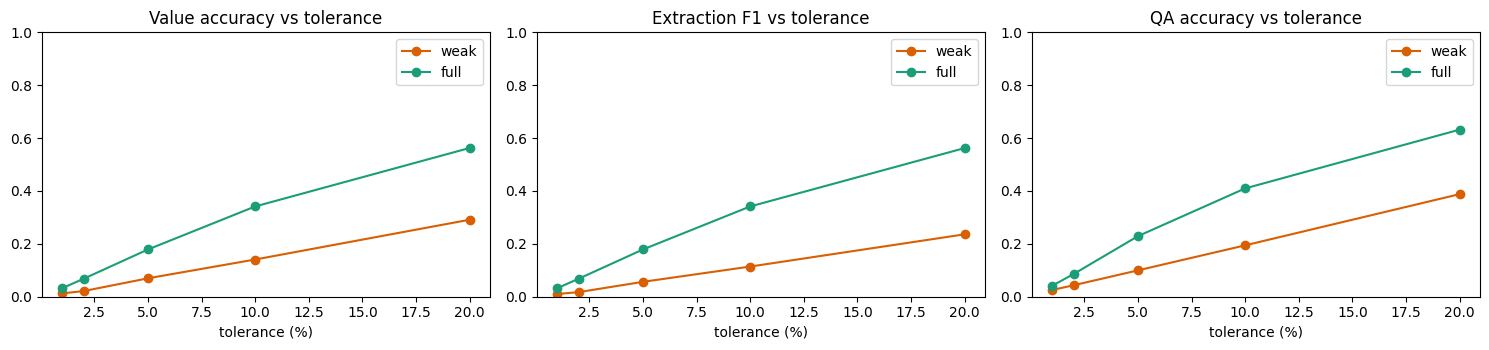

In [22]:
tols = [0.01, 0.02, 0.05, 0.10, 0.20]

rows = []
for name, (V, E) in VT.items():
    for t in tols:
        m = table_metrics(V, E, DS["test"], tol=t)
        rows.append(dict(model=name, tol=t, value_acc=m["value_acc"], extraction_f1=m["extraction_f1"],
                         qa_acc=qa_accuracy(V, E, DS["test"], tol=t)["qa_all"]))
ACC = pd.DataFrame(rows)
display(ACC.pivot(index="tol", columns="model", values=["value_acc", "extraction_f1", "qa_acc"]).round(3))

print("Accuracy at 5% tolerance (test):")
for name in RES.index:
    print(f"  {name:>4}: existence F1 {RES.loc[name, 'exist_f1']:.1%} | value {RES.loc[name, 'value_acc']:.1%} | "
          f"extraction F1 {RES.loc[name, 'extraction_f1']:.1%} | QA {RES.loc[name, 'qa_all']:.1%} "
          f"(direct {RES.loc[name, 'qa_direct']:.1%}, aggregation {RES.loc[name, 'qa_aggregation']:.1%})")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for name, color in [("weak", "#d95f02"), ("full", "#1b9e77")]:
    d = ACC[ACC.model == name]
    ax[0].plot(d.tol * 100, d.value_acc, marker="o", color=color, label=name)
    ax[1].plot(d.tol * 100, d.extraction_f1, marker="o", color=color, label=name)
    ax[2].plot(d.tol * 100, d.qa_acc, marker="o", color=color, label=name)
for a, t in zip(ax, ["Value accuracy vs tolerance", "Extraction F1 vs tolerance", "QA accuracy vs tolerance"]):
    a.set_title(t)
    a.set_xlabel("tolerance (%)")
    a.set_ylim(0, 1)
    a.legend()
plt.tight_layout()
plt.show()

ACC.to_csv(os.path.join(CFG.workdir, "outputs", "accuracy_vs_tolerance.csv"), index=False)

## 12. Demo on fresh synthetic charts
New charts (not in train / val / test) with the original question programs, to compare weak and full answers with the gold answer.

In [23]:
def new_sample(seed):
    rng = np.random.default_rng(seed)
    V, cats, series = make_table(rng)
    ctype = str(rng.choice(["bar", "line"]))

    fig, ax = plt.subplots(figsize=(6, 4), dpi=80)
    colors = list(rng.choice(PALETTE, V.shape[1], replace=False))
    x = np.arange(V.shape[0])

    if ctype == "bar":
        width = 0.8 / V.shape[1]
        for j in range(V.shape[1]):
            ax.bar(x - 0.4 + width * (j + 0.5), V[:, j], width, color=colors[j], label=series[j])
    else:
        for j in range(V.shape[1]):
            ax.plot(x, V[:, j], marker="o", color=colors[j], label=series[j])

    ax.set_xticks(x)
    ax.set_xticklabels(cats, rotation=30, fontsize=8)
    ax.set_ylim(0, V.max() * 1.15)
    if V.shape[1] > 1:
        ax.legend(fontsize=7)
    ax.set_title("Demo Sample", fontsize=10)
    fig.tight_layout()

    buf = io.BytesIO()
    fig.savefig(buf, format='png')
    plt.close(fig)
    buf.seek(0)
    img = Image.open(buf)

    qa = gen_qa(V, cats, series, rng, 20)
    return img, V, qa

In [24]:
MODELS = {
    "weak": weak_model,
    "full": full_model
}


def predict_table(img, name):
    model = MODELS[name]
    f, m = ENC.encode([img.convert("RGB")])
    f_tensor = torch.from_numpy(f).to(DEVICE)
    m_tensor = torch.from_numpy(m).to(DEVICE)

    model.eval()
    with torch.no_grad():
        V, E = model(f_tensor, m_tensor)
    return V[0].cpu(), E[0].cpu()

In [25]:
def run_demo_cases(cases):
    summary = []
    for seed, questions in cases.items():
        img, V, qa = new_sample(seed)
        G = np.array(V)
        names = list(MODELS)

        fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
        axes[0].imshow(img); axes[0].axis("off"); axes[0].set_title(f"seed {seed}", fontsize=10)
        draw_table(axes[1], G, None, "gold table")
        preds = {}
        for k, name in enumerate(names):
            Vp, Ep = predict_table(img, name)
            preds[name] = (Vp, Ep)
            draw_table(axes[2 + k], Vp.numpy(), G, name, exist=(Ep > 0).numpy())
        plt.tight_layout(); plt.show()

        for question in questions:
            q = next((x for x in qa if x["q"] == question), None)
            if q is None:
                print(f"  [seed {seed}] question not generated, skipped: {question}")
                continue
            t = lambda x: torch.tensor([[int(x)]])
            line = f"  [{q['op']:8s}] {question}  | gold = {q['ans']:.2f}"
            row = dict(seed=seed, op=q["op"], gold=round(q["ans"], 2))
            for name in names:
                Vp, Ep = preds[name]
                ans = execute(Vp[None], Ep[None], torch.tensor([[OP_ID[q["op"]]]]),
                              t(q["r1"]), t(q["c1"]), t(q["r2"]), hard=True).item()
                ok = abs(ans - q["ans"]) <= CFG.tol * abs(q["ans"])
                line += f" | {name}: {ans:.2f} {'Correct' if ok else 'Not'}"
                row[name] = ok
            print(line)
            summary.append(row)
        print()

    df = pd.DataFrame(summary)
    if len(df):
        print("Answer accuracy over demo cases:", {n: f"{df[n].mean():.0%}" for n in MODELS})
        print("By operation:")
        display(df.groupby("op")[list(MODELS)].mean().round(2))
    return df

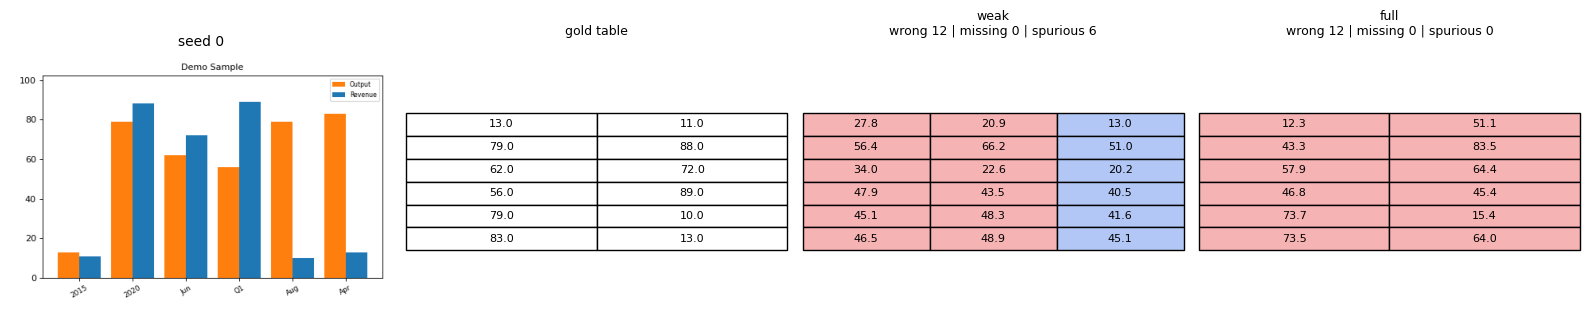

  [max_col ] What is the highest value of Output?  | gold = 83.00 | weak: 56.44 Not | full: 73.71 Not
  [lookup  ] What is the value of Output for Q1?  | gold = 56.00 | weak: 47.90 Not | full: 46.77 Not
  [sum_row ] What is the sum of all series for Apr?  | gold = 96.00 | weak: 140.47 Not | full: 137.44 Not
  [min_col ] What is the lowest value of Revenue?  | gold = 10.00 | weak: 20.86 Not | full: 15.39 Not



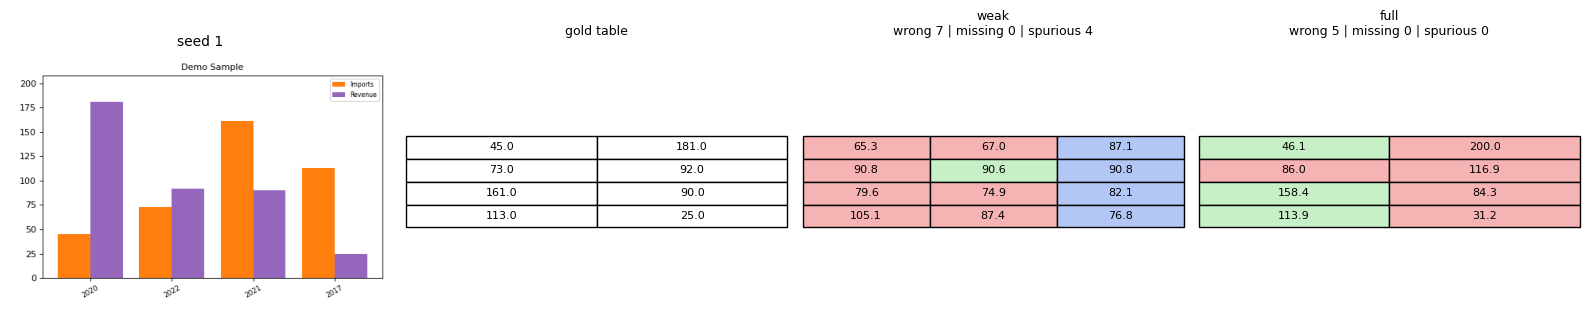

  [sum_col ] What is the total Revenue across all categories?  | gold = 388.00 | weak: 319.83 Not | full: 432.46 Not
  [lookup  ] What is the value of Imports for 2020?  | gold = 45.00 | weak: 65.34 Not | full: 46.12 Correct
  [sum_row ] What is the sum of all series for 2022?  | gold = 165.00 | weak: 272.21 Not | full: 202.89 Not
  [min_col ] What is the lowest value of Imports?  | gold = 45.00 | weak: 65.34 Not | full: 46.12 Correct



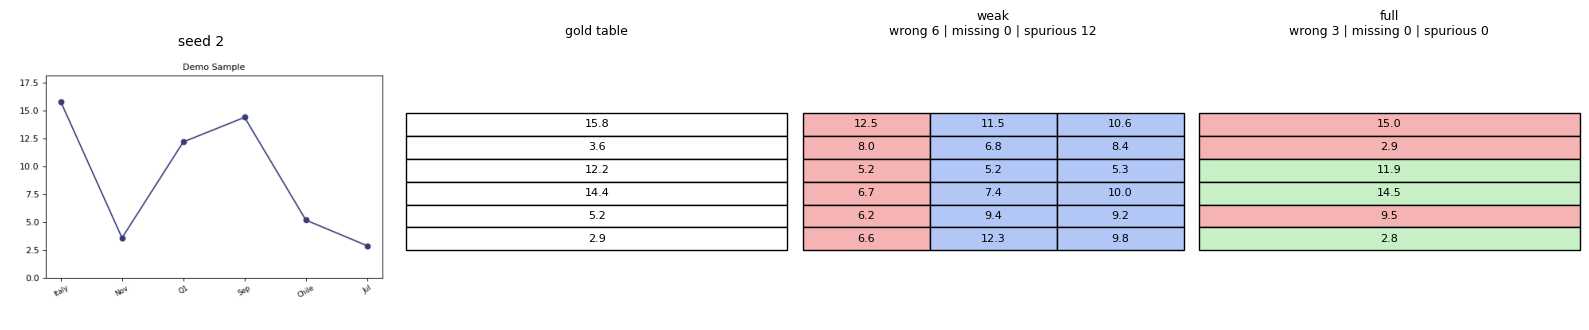

  [max_col ] What is the highest value of Exports?  | gold = 15.80 | weak: 12.46 Not | full: 15.01 Not
  [lookup  ] What is the value of Exports for Q1?  | gold = 12.20 | weak: 5.25 Not | full: 11.92 Correct
  [diff    ] What is the difference in Exports between Sep and Jul?  | gold = 11.50 | weak: 0.09 Not | full: 11.72 Correct
  [sum_col ] What is the total Exports across all categories?  | gold = 54.10 | weak: 45.24 Not | full: 56.73 Correct



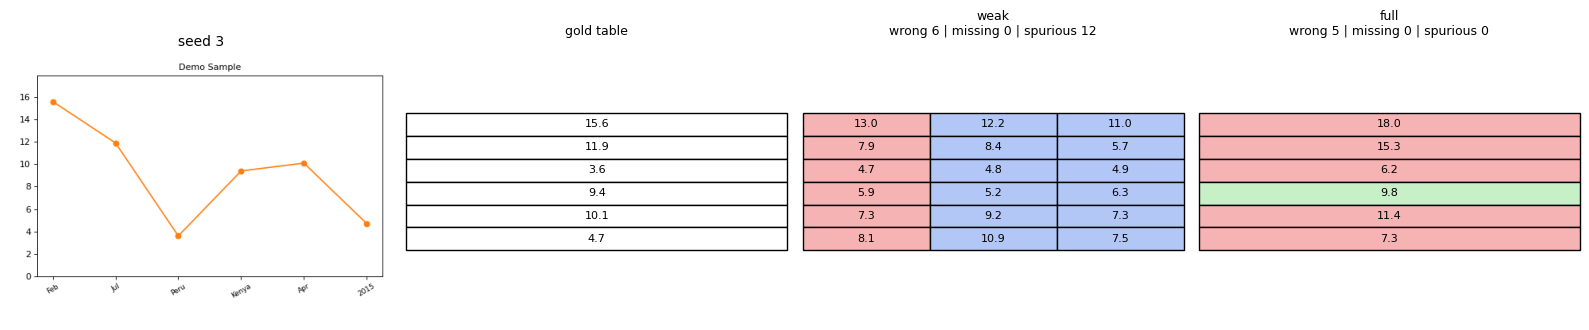

  [lookup  ] What is the value of Exports for Apr?  | gold = 10.10 | weak: 7.33 Not | full: 11.40 Not
  [max_col ] What is the highest value of Exports?  | gold = 15.60 | weak: 13.03 Not | full: 18.00 Not
  [mean_col] What is the average Exports across all categories?  | gold = 9.22 | weak: 7.82 Not | full: 11.31 Not
  [sum_col ] What is the total Exports across all categories?  | gold = 55.30 | weak: 46.92 Not | full: 67.86 Not



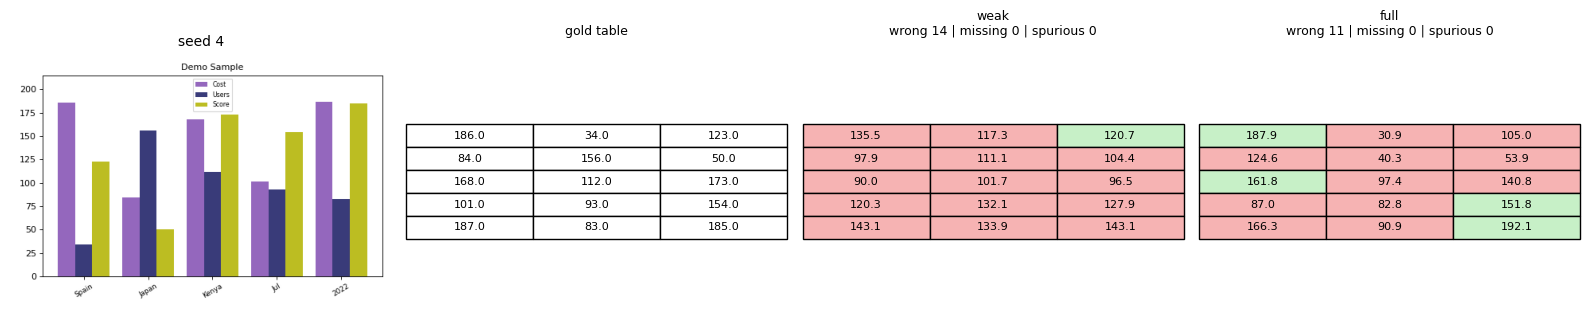

  [sum_row ] What is the sum of all series for Kenya?  | gold = 453.00 | weak: 288.29 Not | full: 400.04 Not
  [lookup  ] What is the value of Cost for Japan?  | gold = 84.00 | weak: 97.86 Not | full: 124.64 Not
  [max_col ] What is the highest value of Score?  | gold = 185.00 | weak: 143.13 Not | full: 192.13 Correct
  [mean_col] What is the average Cost across all categories?  | gold = 145.20 | weak: 117.35 Not | full: 145.51 Correct



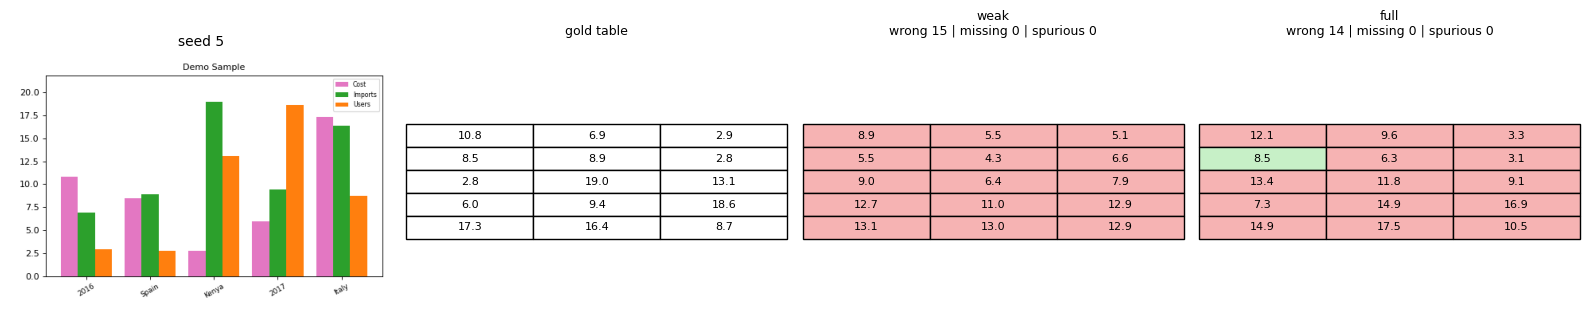

  [diff    ] What is the difference in Users between Spain and Italy?  | gold = 5.90 | weak: 6.37 Not | full: 7.44 Not
  [lookup  ] What is the value of Users for 2017?  | gold = 18.60 | weak: 12.92 Not | full: 16.90 Not
  [sum_col ] What is the total Cost across all categories?  | gold = 45.40 | weak: 49.24 Not | full: 56.19 Not
  [max_col ] What is the highest value of Imports?  | gold = 19.00 | weak: 13.02 Not | full: 17.47 Not

Answer accuracy over demo cases: {'weak': '0%', 'full': '29%'}
By operation:


,weak,full
op,,
diff,0.0,0.50
lookup,0.0,0.33
max_col,0.0,0.20
mean_col,0.0,0.50
min_col,0.0,0.50
sum_col,0.0,0.25
sum_row,0.0,0.00


In [26]:
# every question is drawn from the questions actually generated for each seed, so none is silently skipped
DEMO_CASES = {}
for seed in [0, 1, 2, 3, 4, 5]:
    _, _, qa_ = new_sample(seed)
    picked, seen = [], set()
    for q in qa_:
        if q["op"] not in seen:
            seen.add(q["op"])
            picked.append(q["q"])
    DEMO_CASES[seed] = picked[:4]

demo_df = run_demo_cases(DEMO_CASES)